#  Clase práctica integrada de GeoIA
## Operaciones espaciales, clasificación y cartografía interactiva


### Pregunta guía

> **¿Cómo pasamos de “tener capas geográficas” a construir evidencia espacial útil para tomar decisiones?**

La clase se organiza como una única secuencia analítica:

$$
\text{Auditar datos}
\rightarrow
\text{proyectar}
\rightarrow
\text{cruzar geometrías}
\rightarrow
\text{agregar}
\rightarrow
\text{clasificar}
\rightarrow
\text{comunicar}
$$

### Lo que integra y mejora esta clase

- `overlay()` y relaciones geométricas.
- `dissolve()` y agregación espacial.
- `sjoin()` para relaciones punto–polígono.
- Cálculo correcto de áreas y distancias en CRS proyectados.
- Clasificación con **Equal Interval, Quantiles y Fisher–Jenks**.
- Mapas estáticos profesionales con `geopandas` + `contextily`.
- Mapas interactivos con `folium`, tooltips, capas y clusters.
- Un caso final de nivel fuerte aplicado al **Perú** que conecta todo lo anterior.

> **Corrección conceptual importante:** `contextily` trabaja naturalmente con Web Mercator (EPSG:3857), mientras que `folium` debe recibir coordenadas geográficas en **WGS84 (EPSG:4326)**.



## 0. Preparación del entorno

Los archivos base de esta práctica son los GeoJSON adjuntos.  
El notebook intenta encontrarlos en `/content`, una carpeta `data/` o `/mnt/data`.

Si estás en Colab y no los encuentra, abrirá un selector para cargarlos.


In [ ]:

!pip -q install mapclassify contextily folium branca xyzservices

In [ ]:

import sys, warnings, math, json, os, re
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify
import contextily as ctx
import folium
import branca
import requests

from shapely.geometry import Point
from pyproj import CRS
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("GeoPandas:", gpd.__version__)
print("Mapclassify:", mapclassify.__version__)
print("Folium:", folium.__version__)


GeoPandas: 1.2.0
Mapclassify: 2.10.0
Folium: 0.20.0


In [ ]:
# Aquí defines los archivos base que tu proyecto necesita para funcionar.
EXPECTED = [
    "chicago.geojson",
    "groceries.geojson",
    "OS_Boundaryline_7457434618637060681.geojson",
    "london_constituencies_sur.geojson",
    "london_constituencies_norte.geojson",
    "NY_counties_shoreline.geojson",
]

# Defines los directorios donde se buscarán los archivos.
SEARCH_DIRS = [
    Path("/content"),
    Path("/content/data"),
    Path.cwd(),
    Path.cwd() / "data",
    Path("/mnt/data"),
]

# Función para resolver la ubicación de un archivo
def resolve_file(filename):
    for d in SEARCH_DIRS:
        p = d / filename
        if p.exists():
            return p
    # búsqueda recursiva corta en Colab / directorio actual
    for root in [Path("/content"), Path.cwd()]:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    return None

# Genera una lista de archivos que no fueron encontrados.
missing = [f for f in EXPECTED if resolve_file(f) is None]

# Si resolve_file devuelve None, significa que el archivo está ausente.
if missing and "google.colab" in sys.modules:
    print("Faltan archivos:", missing)
    from google.colab import files
    _ = files.upload()

# Subida manual en Colab (si faltan archivos)
missing = [f for f in EXPECTED if resolve_file(f) is None]
if missing:
    print("⚠️ Aún faltan archivos:", missing)
else:
    print("✅ Todos los archivos base fueron localizados.")


✅ Todos los archivos base fueron localizados.



## 1. Auditoría espacial antes de analizar

Antes de cualquier cálculo hay cuatro preguntas obligatorias:

1. ¿Qué tipo de geometría tiene cada capa?
2. ¿Qué CRS utiliza?
3. ¿Las geometrías son válidas?
4. ¿La extensión espacial corresponde a lo que creemos que contiene el archivo?

Una gran parte de los errores en análisis geoespacial ocurre **antes** del modelo: datos mal interpretados, CRS incorrectos o geometrías defectuosas.


In [ ]:
# Función de auditoría de capas
def audit_layer(name, gdf):
    b = gdf.total_bounds # obtiene la extensión espacial (xmin, ymin, xmax, ymax)
    return {
        "capa": name,
        "n": len(gdf), #  número de registros (features)
        "crs": str(gdf.crs), # sistema de referencia espacial.
        "geometrias": ", ".join(gdf.geom_type.value_counts().index.tolist()), #tipos de geometrías presentes (ej. Polígono, Punto)
        "validas_pct": round(100 * gdf.geometry.is_valid.mean(), 1), # proporción de geometrías válidas
        "xmin": round(b[0], 3),
        "ymin": round(b[1], 3),
        "xmax": round(b[2], 3),
        "ymax": round(b[3], 3),
    } # Devuelve un diccionario con toda esta información.

# Función para limpiar geometrías
def clean_geometries(gdf):
    gdf = gdf.copy()
    if hasattr(gdf.geometry, "make_valid"): # make_valid() → corrige geometrías inválidas (si está disponible en la librería)
        gdf["geometry"] = gdf.geometry.make_valid()
    else:
        gdf["geometry"] = gdf.buffer(0) # truco clásico para reparar geometrías problemáticas (ej. polígonos con autointersecciones)
    return gdf

# Lectura y limpieza de archivos GeoJSON
chicago = clean_geometries(gpd.read_file(resolve_file("chicago.geojson")))
groceries = clean_geometries(gpd.read_file(resolve_file("groceries.geojson")))
london = clean_geometries(gpd.read_file(resolve_file("OS_Boundaryline_7457434618637060681.geojson")))
london_south = clean_geometries(gpd.read_file(resolve_file("london_constituencies_sur.geojson")))
london_north = clean_geometries(gpd.read_file(resolve_file("london_constituencies_norte.geojson")))
ny = clean_geometries(gpd.read_file(resolve_file("NY_counties_shoreline.geojson")))
# Cada capa se pasa por clean_geometries() para garantizar que las geometrías sean válidas

# Auditoría de todas las capas
audit = pd.DataFrame([
    audit_layer("Chicago communities", chicago),
    audit_layer("Groceries", groceries),
    audit_layer("London", london),
    audit_layer("London South", london_south),
    audit_layer("London North", london_north),
    audit_layer("NY counties", ny),
]) # Los resultados se almacenan en un DataFrame de Pandas

display(audit)


,capa,n,crs,geometrias,validas_pct,xmin,ymin,xmax,ymax
0,Chicago communities,77,EPSG:4326,"MultiPolygon, Polygon",100.0,-87.940,41.645,-87.524,42.023
1,Groceries,148,EPSG:4326,MultiPoint,100.0,-87.818,41.679,-87.584,42.019
2,London,14,EPSG:4326,Polygon,100.0,-0.510,51.287,0.334,51.692
3,London South,6,EPSG:4326,Polygon,100.0,-0.461,51.287,0.224,51.516
4,London North,8,EPSG:4326,Polygon,100.0,-0.510,51.453,0.334,51.692
5,NY counties,62,EPSG:4326,"Polygon, MultiPolygon",100.0,-79.762,40.496,-71.856,45.013



### Punto de control

No calculamos áreas, longitudes o buffers todavía porque las capas están originalmente en coordenadas geográficas (grados).

> **Regla:** geometría topológica puede trabajarse en un CRS común; métricas físicas deben calcularse en un CRS apropiado en metros.



# Bloque A — `overlay()` + `dissolve()`
## Particionar Londres con una máscara espacial

Vamos a usar la capa de circunscripciones del sur como una **máscara**.  
Primero la fusionamos con `dissolve()` y luego comparamos cuatro operaciones:

- Intersección
- Diferencia
- Unión
- Diferencia simétrica

Para Londres usamos **British National Grid (EPSG:27700)**, adecuado para mediciones locales en metros.


In [ ]:
# 1. Reproyección de capas a EPSG:27700 (British National Grid)
# Esto asegura que todas las capas estén en el mismo sistema de coordenadas
# y que las operaciones espaciales sean consistentes.
london_m = london.to_crs(27700)
south_m = london_south.to_crs(27700)
north_m = london_north.to_crs(27700)

# 2. Crear una máscara única para el sur de Londres
# - Se asigna un campo "zona" con valor fijo "Sur"
# - Se disuelven todas las geometrías en una sola (agrupando por "zona")
# - Se reinicia el índice para mantener la tabla limpia
south_mask = (
    south_m
    .assign(zona="Sur")
    .dissolve(by="zona")
    .reset_index()
)

# 3. Selección de atributos base de Londres
# Nos quedamos solo con el nombre de la circunscripción y su geometría
base = london_m[["NAME", "geometry"]]

# 4. Aplicar operaciones de superposición espacial (overlay)
# Se comparan las geometrías de Londres con la máscara del sur
operations = {}
for how in ["intersection", "difference", "union", "symmetric_difference"]:
    operations[how] = gpd.overlay(
        base,                        # capa base
        south_mask[["geometry"]],    # máscara del sur
        how=how,                     # tipo de operación espacial
        keep_geom_type=True          # mantener el tipo de geometría original
    )

# 5. Resumen de resultados
# Se construye una tabla con:
# - Nombre de la operación
# - Número de geometrías resultantes
# - Área total en km² (conversión de m² a km² dividiendo entre 1e6)
summary_overlay = pd.DataFrame({
    "operacion": operations.keys(),
    "n_geometrias": [len(v) for v in operations.values()],
    "area_km2": [v.geometry.area.sum() / 1e6 for v in operations.values()]
})

# 6. Visualización del resumen
# Se muestran los resultados redondeados a 2 decimales
display(summary_overlay.round(2))


,operacion,n_geometrias,area_km2
0,intersection,7,713.15
1,difference,12,881.58
2,union,19,1594.73
3,symmetric_difference,12,881.58


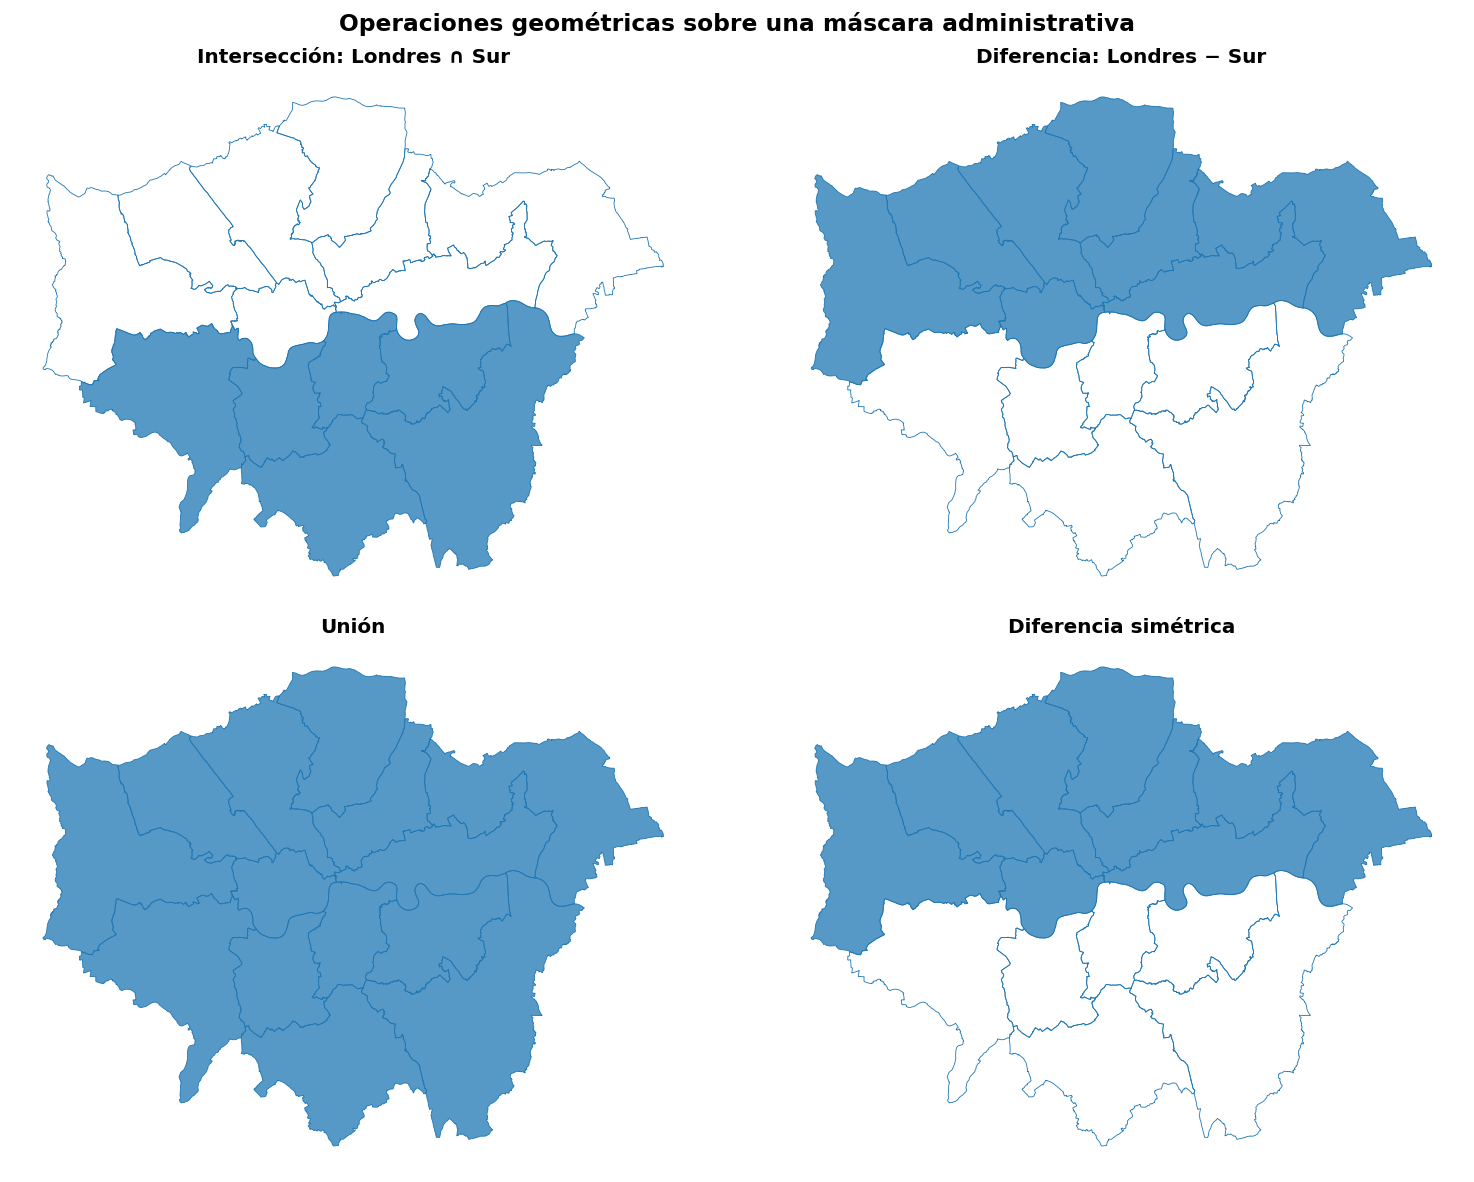

In [ ]:
# 1. Crear una figura con 4 subgráficos (2 filas x 2 columnas)
# Cada subgráfico mostrará una operación espacial distinta
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 2. Diccionario con títulos descriptivos para cada operación
titles = {
    "intersection": "Intersección: Londres ∩ Sur",
    "difference": "Diferencia: Londres − Sur",
    "union": "Unión",
    "symmetric_difference": "Diferencia simétrica",
}

# 3. Iterar sobre cada subgráfico y cada operación
# - Se dibuja el contorno de Londres (boundary)
# - Se dibuja el resultado de la operación (relleno con transparencia)
for ax, (how, gdf_) in zip(axes.flat, operations.items()):
    london_m.boundary.plot(ax=ax, linewidth=0.5)  # contorno de Londres
    gdf_.plot(ax=ax, alpha=0.75)                  # resultado de la operación
    ax.set_title(titles[how], fontweight="bold")  # título del subgráfico
    ax.set_axis_off()                             # quitar ejes para mejor visualización

# 4. Título general de la figura
plt.suptitle("Operaciones geométricas sobre una máscara administrativa",
             fontsize=14, fontweight="bold")

# 5. Ajustar diseño para que los subgráficos no se solapen
plt.tight_layout()

# 6. Mostrar la figura
plt.show()




### ¿Por qué `dissolve()` antes del `overlay()`?

Si queremos tratar “el sur” como una sola región, no conviene cruzar una por una todas sus circunscripciones.  
`dissolve()` transforma el conjunto en una única geometría y reduce complejidad topológica.

**Idea clave:** `dissolve()` no es solo una herramienta de visualización; cambia la **unidad de análisis**.



# Bloque B — `sjoin()` + accesibilidad espacial
## ¿Qué comunidades de Chicago tienen menor oferta relativa de tiendas?

Ahora combinamos:

- Polígonos: comunidades de Chicago.
- Puntos: tiendas de comestibles.
- Población: `POP2010`.

Construiremos una tasa simple:

$$
\text{tiendas por 10\,000 hab.}
=
10\,000\,
\frac{\text{número de tiendas}}{\text{población}}
$$

No interpretaremos esta tasa como “seguridad alimentaria” completa: es un **indicador espacial de oferta relativa**.


In [ ]:
# 1. Algunos registros de la capa de tiendas vienen como MultiPoint.
#    La función explode separa cada MultiPoint en puntos individuales.
#    reset_index(drop=True) reinicia el índice para que quede limpio.
groceries_pts = groceries.explode(index_parts=False).reset_index(drop=True)

# 2. Verificación de sistemas de referencia espacial (CRS).
#    Ambos datasets deben estar en el mismo CRS para hacer operaciones espaciales.
#    EPSG:4326 es el sistema de coordenadas geográficas estándar (lat/lon).
assert chicago.crs == groceries_pts.crs

# 3. Spatial Join (relación espacial punto-en-polígono).
#    Se asigna a cada tienda (punto) la comunidad de Chicago en la que se encuentra.
#    predicate="within" asegura que el punto esté dentro del polígono.
joined = gpd.sjoin(
    groceries_pts,
    chicago[["community", "NID", "POP2010", "geometry"]],
    how="left",
    predicate="within"
)

# 4. Contar cuántos puntos no quedaron asignados a ninguna comunidad.
#    Esto puede ocurrir si están fuera de los límites de Chicago.
n_unmatched = joined["community"].isna().sum()
print("Puntos sin comunidad asignada:", n_unmatched)

# 5. Contar el número de tiendas por comunidad.
#    Se agrupan los puntos por comunidad y se cuenta cuántos hay en cada una.
counts = joined.groupby("community").size().rename("n_groceries")

# 6. Unir los conteos con la capa original de comunidades.
#    Se hace un merge por el campo "community".
chi = chicago.merge(counts, on="community", how="left")

# 7. Rellenar valores faltantes (comunidades sin tiendas) con 0.
#    Convertir a entero para evitar decimales innecesarios.
chi["n_groceries"] = chi["n_groceries"].fillna(0).astype(int)

# 8. Calcular la densidad de tiendas por cada 10,000 habitantes.
#    Fórmula: (número de tiendas / población) * 10,000
#    Si la población es 0, se asigna NaN para evitar división por cero.
chi["stores_per_10k"] = np.where(
    chi["POP2010"] > 0,
    10000 * chi["n_groceries"] / chi["POP2010"],
    np.nan
)

# 9. Mostrar un resumen ordenado de las comunidades con menor densidad de tiendas.
#    Se seleccionan las 12 comunidades con menos tiendas por cada 10,000 habitantes.
display(
    chi[["community", "POP2010", "n_groceries", "stores_per_10k"]]
    .sort_values("stores_per_10k")
    .head(12)
    .round(2)
)

Puntos sin comunidad asignada: 0


,community,POP2010,n_groceries,stores_per_10k
1,OAKLAND,5918,0,0.0
2,FULLER PARK,2876,0,0.0
3,GRAND BOULEVARD,21929,0,0.0
4,KENWOOD,17841,0,0.0
6,WASHINGTON PARK,11717,0,0.0
26,WEST GARFIELD PARK,18001,0,0.0
27,EAST GARFIELD PARK,20567,0,0.0
20,HERMOSA,25010,0,0.0
48,EAST SIDE,23042,0,0.0
49,WEST PULLMAN,29651,0,0.0



### Clasificación: el mapa depende del método

Aplica tres métodos de clasificación estadística a la variable densidad de tiendas por cada 10,000 habitantes en las comunidades de Chicago:

Vamos a comparar:

- **Equal Interval:** divide el rango de valores en intervalos iguales.
- **Quantiles:** asegura que cada clase tenga el mismo número de comunidades.
- **Fisher–Jenks:** optimiza la agrupación minimizando la variabilidad interna.


In [ ]:
# 1. Preparar la variable de análisis
# Se toma la columna "stores_per_10k" (tiendas por cada 10,000 habitantes)
# Se reemplazan valores faltantes con 0 y se convierte a un array NumPy.
y = chi["stores_per_10k"].fillna(0).to_numpy()

# 2. Definir el número de clases (categorías)
# Aquí se decide dividir los datos en 5 clases.
k = 5

# 3. Crear clasificadores espaciales con diferentes métodos
# - Equal Interval: divide el rango en intervalos iguales
# - Quantiles: divide los datos en grupos con igual número de observaciones
# - Fisher–Jenks: método estadístico que minimiza la varianza dentro de clases
classifiers_chi = {
    "Equal Interval": mapclassify.EqualInterval(y, k=k),
    "Quantiles": mapclassify.Quantiles(y, k=k),
    "Fisher–Jenks": mapclassify.FisherJenks(y, k=k),
}

# 4. Comparar resultados de los clasificadores
# Se construye una lista con:
# - Nombre del método
# - Cortes (umbrales de cada clase)
# - Conteos (cuántas observaciones caen en cada clase)
comparison = []
for name, clf in classifiers_chi.items():
    comparison.append({
        "metodo": name,
        "cortes": np.round(clf.bins, 3).tolist(),
        "conteos": clf.counts.tolist(),
    })

# 5. Mostrar la comparación en una tabla
# Se convierte la lista en un DataFrame y se visualiza.
display(pd.DataFrame(comparison))



,metodo,cortes,conteos
0,Equal Interval,"[0.512, 1.025, 1.537, 2.05, 2.562]","[44, 21, 8, 2, 2]"
1,Quantiles,"[0.0, 0.26, 0.541, 0.889, 2.562]","[23, 8, 15, 15, 16]"
2,Fisher–Jenks,"[0.205, 0.562, 0.967, 1.493, 2.562]","[28, 21, 16, 8, 4]"


La tabla te está mostrando cómo distintos métodos de clasificación dividen la misma variable en categorías.

* Los cortes son los límites de cada clase.

* Los conteos son cuántas comunidades caen en cada clase.

* La diferencia entre métodos refleja distintas formas de interpretar la distribución de la densidad de tiendas en Chicago.

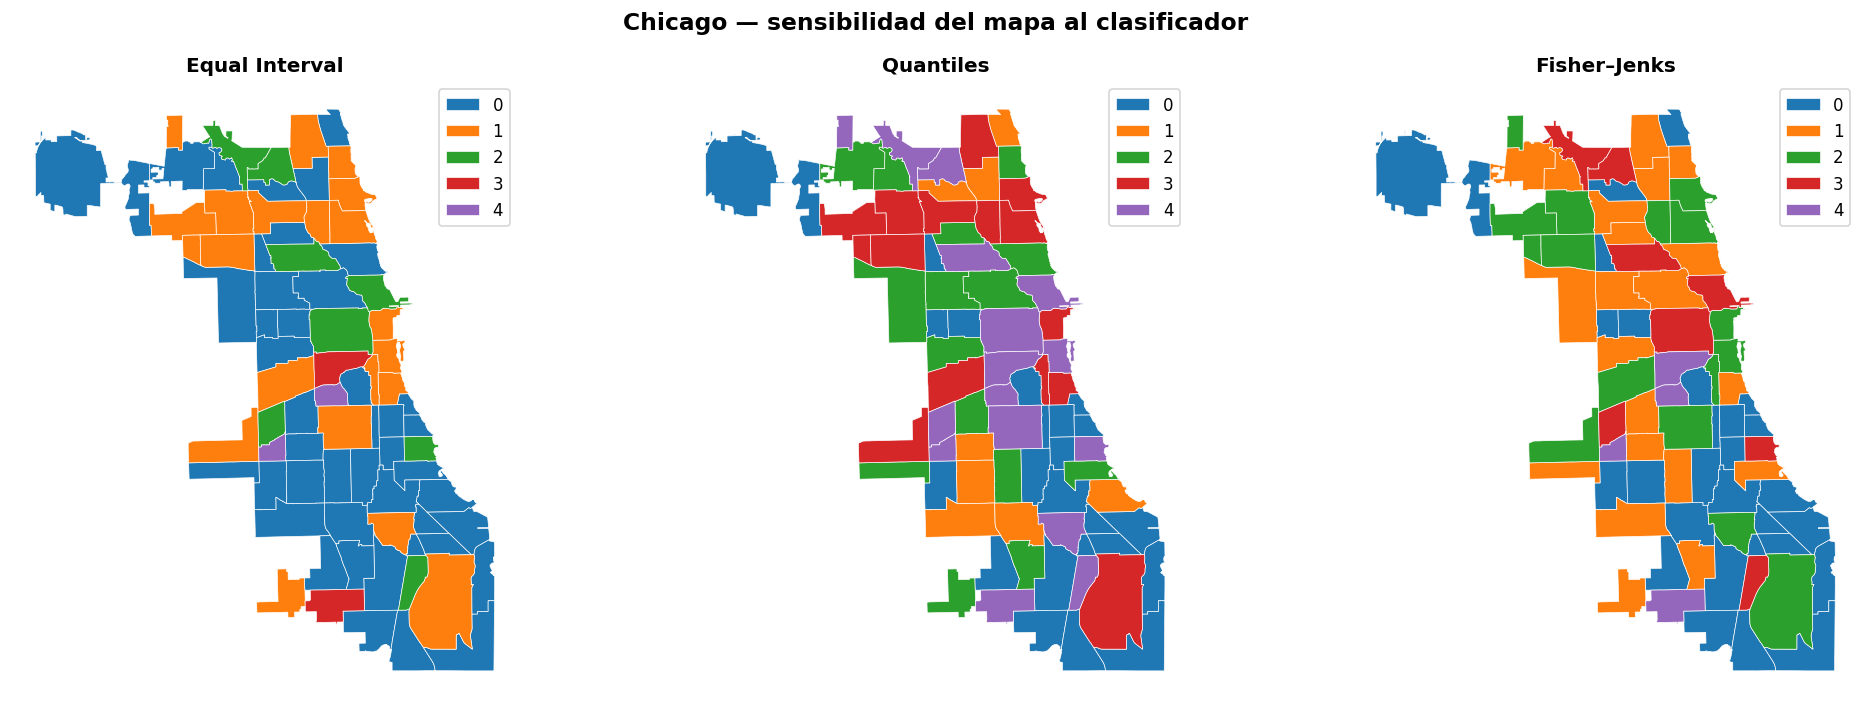

In [ ]:
# 1. Crear una figura con 3 subgráficos en una sola fila
# Cada subgráfico mostrará un mapa con un método de clasificación distinto
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

# 2. Iterar sobre cada clasificador y cada subgráfico
# classifiers_chi contiene los clasificadores (Equal Interval, Quantiles, Fisher–Jenks)
for ax, (name, clf) in zip(axes, classifiers_chi.items()):
    # Copiar el GeoDataFrame original de comunidades de Chicago
    tmp = chi.copy()

    # Añadir una columna "clase" con la categoría asignada por el clasificador
    # clf.yb devuelve el índice de clase para cada comunidad
    tmp["clase"] = clf.yb

    # Dibujar el mapa temático
    tmp.plot(
        ax=ax,                  # subgráfico donde se dibuja
        column="clase",         # columna que define la categoría
        categorical=True,       # indicar que son clases discretas
        legend=True,            # mostrar leyenda con las clases
        edgecolor="white",      # bordes blancos para separar polígonos
        linewidth=0.4           # grosor de los bordes
    )

    # Asignar título al subgráfico con el nombre del método
    ax.set_title(name, fontweight="bold")

    # Quitar los ejes para que el mapa se vea más limpio
    ax.set_axis_off()

# 3. Título general para toda la figura
plt.suptitle("Chicago — sensibilidad del mapa al clasificador",
             fontsize=14, fontweight="bold")

# 4. Ajustar el diseño para que los subgráficos no se solapen
plt.tight_layout()

# 5. Mostrar la figura final
plt.show()



### Mapa estático con contexto

Para un mapa base con `contextily`, reproyectamos a **EPSG:3857**.

Esto contrasta con `folium`, donde posteriormente volveremos a **EPSG:4326**.


In [ ]:
# 1. Inicializar la figura y el eje del mapa
# Se crea un lienzo de 10x10 pulgadas para dibujar el mapa
fig, my_map = plt.subplots(figsize=(10, 10))

# 2. Reproyectar las capas a EPSG:3857 (Web Mercator)
# Este sistema de coordenadas es el estándar para mapas web y basemaps
chi_3857 = chi.to_crs(3857)
gro_3857 = groceries_pts.to_crs(3857)

# 3. Dibujar las comunidades de Chicago
# - Se colorean según la variable "stores_per_10k" (tiendas por cada 10,000 habitantes)
# - Se usa el esquema de clasificación Fisher–Jenks con 5 clases
# - Se ajusta transparencia, bordes y se añade leyenda
chi_3857.plot(
    ax=my_map,
    column="stores_per_10k",
    scheme="FisherJenks",
    k=5,
    alpha=0.68,
    edgecolor="white",
    linewidth=0.35,
    legend=True,
    legend_kwds={"title": "Tiendas por 10 mil hab."},
)

# 4. Dibujar las tiendas de comestibles como puntos
# Se representan con tamaño 10 y cierta transparencia
gro_3857.plot(ax=my_map, markersize=10, alpha=0.55)

# 5. Añadir un mapa base
# Se usa Esri WorldStreetMap como fondo seguro y alternativo
ctx.add_basemap(my_map, source=ctx.providers.Esri.WorldStreetMap)

# (Opcional) Se podría usar otro proveedor como WorldImagery
# ctx.add_basemap(my_map, source=ctx.providers.Esri.WorldImagery)

# 6. Ajustes finales del mapa
# - Título descriptivo
# - Se eliminan los ejes para que se vea más limpio
# - Se ajusta el diseño para evitar solapamientos
my_map.set_title("Chicago — oferta relativa de tiendas de comestibles",
                 fontsize=14, fontweight="bold")
my_map.set_axis_off()
plt.tight_layout()

# 7. Mostrar el mapa final
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import contextily as ctx

# 1. Inicializar la figura y el eje del mapa
# Se crea un lienzo de 8x8 pulgadas para dibujar el mapa
fig, my_map = plt.subplots(figsize=(8, 8))

# 2. Reproyectar las capas a EPSG:3857 (Web Mercator)
# Este sistema de coordenadas es el estándar para mapas web y basemaps
chi_3857 = chi.to_crs(3857)
gro_3857 = groceries_pts.to_crs(3857)

# 3. Dibujar las comunidades de Chicago
# - Se colorean según la variable "stores_per_10k" (tiendas por cada 10,000 habitantes)
# - Se usa el esquema de clasificación Fisher–Jenks con 5 clases
# - Se ajusta transparencia, bordes y se añade leyenda
chi_3857.plot(
    ax=my_map,
    column="stores_per_10k",
    scheme="FisherJenks",
    k=5,
    alpha=0.68,
    edgecolor="white",
    linewidth=0.35,
    legend=True,
    legend_kwds={"title": "Tiendas por 10 mil hab."},
)

# 4. Dibujar las tiendas de comestibles como puntos
# Se representan con tamaño 10 y cierta transparencia
gro_3857.plot(ax=my_map, markersize=10, alpha=0.55)

# 5. Añadir un mapa base
# Aquí se usa Esri WorldImagery (imágenes satelitales) como fondo
# Se podría alternar con Esri WorldStreetMap para un estilo más urbano
ctx.add_basemap(my_map, source=ctx.providers.Esri.WorldImagery)

# 6. Ajustes finales del mapa
# - Título descriptivo
# - Se eliminan los ejes para que se vea más limpio
# - Se ajusta el diseño para evitar solapamientos
my_map.set_title("Chicago — oferta relativa de tiendas de comestibles",
                 fontsize=14, fontweight="bold")
my_map.set_axis_off()
plt.tight_layout()

# 7. Mostrar el mapa final
plt.show()


# Bloque C — Clasificación espacial con una variable territorial real
## Cambio poblacional 2010–2020 en condados de Nueva York

Definimos:

$$
g_i =
100\,
\frac{\text{POP2020}_i-\text{POP2010}_i}
{\text{POP2010}_i}
$$

y evaluamos cómo cambia la lectura cartográfica con tres clasificadores.


In [ ]:
# 1. Crear una copia del GeoDataFrame original de Nueva York
# Esto evita modificar directamente la capa 'ny'
nyc = ny.copy()

# 2. Calcular el porcentaje de crecimiento poblacional entre 2010 y 2020
# Fórmula: ((POP2020 - POP2010) / POP2010) * 100
nyc["growth_pct"] = 100 * (nyc["POP2020"] - nyc["POP2010"]) / nyc["POP2010"]

# 3. Mostrar los 10 condados con menor crecimiento (o decrecimiento)
# - Se seleccionan las columnas relevantes
# - Se ordenan por 'growth_pct' de menor a mayor
# - Se muestran los primeros 10 registros
# - Se redondean los valores a 2 decimales
display(
    nyc[["NAME", "POP2010", "POP2020", "growth_pct"]]
    .sort_values("growth_pct")
    .head(10)
    .round(2)
)

# 4. Mostrar un resumen estadístico del crecimiento poblacional
# - count: número de condados
# - mean: crecimiento promedio
# - std: desviación estándar
# - min / max: valores extremos
# - 25%, 50%, 75%: percentiles de la distribución
print("\nResumen:")
display(nyc["growth_pct"].describe().round(2).to_frame("growth_pct"))

In [ ]:
# 1. Preparar la variable de análisis
# Se toma la columna "growth_pct" (crecimiento poblacional 2010–2020 en %)
# y se convierte en un array NumPy para usarlo en los clasificadores.
y_ny = nyc["growth_pct"].to_numpy()

# 2. Definir clasificadores estadísticos con 5 clases (k=5)
# - Equal Interval: divide el rango en intervalos iguales
# - Quantiles: divide los datos en grupos con igual número de observaciones
# - Fisher–Jenks: encuentra cortes "naturales" que minimizan la variabilidad interna
classifiers_ny = {
    "Equal Interval": mapclassify.EqualInterval(y_ny, k=5),
    "Quantiles": mapclassify.Quantiles(y_ny, k=5),
    "Fisher–Jenks": mapclassify.FisherJenks(y_ny, k=5),
}

# 3. Crear una figura con 3 subgráficos en una sola fila
# Cada subgráfico mostrará un mapa con un método de clasificación distinto
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 4. Iterar sobre cada clasificador y cada subgráfico
for ax, (name, clf) in zip(axes, classifiers_ny.items()):
    # Copiar el GeoDataFrame original de Nueva York
    tmp = nyc.copy()

    # Añadir una columna "clase" con la categoría asignada por el clasificador
    # clf.yb devuelve el índice de clase para cada condado
    tmp["clase"] = clf.yb

    # Dibujar el mapa temático
    tmp.plot(
        ax=ax,                  # subgráfico donde se dibuja
        column="clase",         # columna que define la categoría
        categorical=True,       # indicar que son clases discretas
        legend=True,            # mostrar leyenda con las clases
        edgecolor="white",      # bordes blancos para separar polígonos
        linewidth=0.35          # grosor de los bordes
    )

    # Asignar título al subgráfico con el nombre del método
    ax.set_title(name, fontweight="bold")

    # Quitar los ejes para que el mapa se vea más limpio
    ax.set_axis_off()

# 5. Título general para toda la figura
plt.suptitle("Nueva York — cambio poblacional 2010–2020",
             fontsize=14, fontweight="bold")

# 6. Ajustar el diseño para que los subgráficos no se solapen
plt.tight_layout()

# 7. Mostrar la figura final
plt.show()

In [ ]:
import contextily as ctx
import matplotlib.pyplot as plt
import mapclassify

# 1. Reproyectar la capa de Nueva York a EPSG:3857 (Web Mercator)
# Este sistema de coordenadas es el estándar para mapas web y basemaps.
nyc = nyc.to_crs(epsg=3857)

# 2. Preparar la variable de análisis
# Se toma la columna "growth_pct" (crecimiento poblacional 2010–2020 en %)
# y se convierte en un array NumPy para usarlo en los clasificadores.
y_ny = nyc["growth_pct"].to_numpy()

# 3. Definir clasificadores estadísticos con 5 clases (k=5)
# - Equal Interval: divide el rango en intervalos iguales
# - Quantiles: divide los datos en grupos con igual número de observaciones
# - Fisher–Jenks: encuentra cortes "naturales" que minimizan la variabilidad interna
classifiers_ny = {
    "Equal Interval": mapclassify.EqualInterval(y_ny, k=5),
    "Quantiles": mapclassify.Quantiles(y_ny, k=5),
    "Fisher–Jenks": mapclassify.FisherJenks(y_ny, k=5),
}

# 4. Crear una figura con 3 subgráficos en una sola fila
# Cada subgráfico mostrará un mapa con un método de clasificación distinto
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 5. Iterar sobre cada clasificador y cada subgráfico
for ax, (name, clf) in zip(axes, classifiers_ny.items()):
    # Copiar el GeoDataFrame original de Nueva York
    tmp = nyc.copy()

    # Añadir una columna "clase" con la categoría asignada por el clasificador
    # clf.yb devuelve el índice de clase para cada condado
    tmp["clase"] = clf.yb

    # Dibujar el mapa temático
    tmp.plot(
        ax=ax,                  # subgráfico donde se dibuja
        column="clase",         # columna que define la categoría
        categorical=True,       # indicar que son clases discretas
        legend=True,            # mostrar leyenda con las clases
        edgecolor="white",      # bordes blancos para separar polígonos
        linewidth=0.35          # grosor de los bordes
    )

    # 6. Añadir un mapa base debajo
    # Se usa Esri WorldStreetMap como fondo para dar contexto geográfico
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldStreetMap)

    # Asignar título al subgráfico con el nombre del método
    ax.set_title(name, fontweight="bold")

    # Quitar los ejes para que el mapa se vea más limpio
    ax.set_axis_off()

# 7. Título general para toda la figura
plt.suptitle("Nueva York — cambio poblacional 2010–2020",
             fontsize=14, fontweight="bold")

# 8. Ajustar el diseño para que los subgráficos no se solapen
plt.tight_layout()

# 9. Mostrar la figura final
plt.show()



### Lectura crítica

Un clasificador no “descubre la verdad”; transforma una variable continua en categorías.

**Preguntas para discutir:**
- ¿Cambian visualmente los condados “extremos”?
- ¿Qué método usarías para comparar posiciones relativas?
- ¿Cuál usarías si buscas agrupamientos naturales?
- ¿Qué riesgo existe si se eligen cortes solo para “hacer más dramático” un mapa?



# Bloque D — Cartografía interactiva con `folium`
## Comunidades + tiendas + tooltip + cluster

Para `folium` mantenemos todo en **EPSG:4326**.

El mapa tendrá:
- Coroplético por `stores_per_10k`.
- Tooltips por comunidad.
- Cluster de tiendas.
- Control de capas.


In [ ]:
from folium.plugins import MarkerCluster
import folium
import branca

# 1. Reproyectar las capas a EPSG:4326 (lat/lon estándar)
# Folium trabaja en coordenadas geográficas (WGS84), por eso se usa este CRS.
chi_web = chi.to_crs(4326).copy()
gro_web = groceries_pts.to_crs(4326).copy()

# 2. Definir la escala de colores para el mapa coroplético
# Se toma el mínimo y máximo de la variable "stores_per_10k"
vmin = float(chi_web["stores_per_10k"].min())
vmax = float(chi_web["stores_per_10k"].max())
colormap = branca.colormap.linear.YlOrRd_09.scale(vmin, vmax)
colormap.caption = "Tiendas de comestibles por 10 mil habitantes"

# 3. Crear el mapa base centrado en Chicago
# - location: coordenadas aproximadas de Chicago
# - zoom_start: nivel inicial de zoom
# - tiles: estilo del mapa base (CartoDB positron)
# - control_scale: añade escala gráfica
m_chicago = folium.Map(
    location=[41.84, -87.68],
    zoom_start=10,
    tiles="CartoDB positron",
    control_scale=True
)

# 4. Añadir las comunidades de Chicago como polígonos
# - Se colorean según la variable "stores_per_10k"
# - Se define un estilo con color de relleno, borde y transparencia
# - Se añade un tooltip con información contextual
folium.GeoJson(
    chi_web[["community", "POP2010", "n_groceries", "stores_per_10k", "geometry"]].to_json(),
    name="Comunidades",
    style_function=lambda f: {
        "fillColor": colormap(f["properties"]["stores_per_10k"]),
        "color": "#444444",
        "weight": 0.7,
        "fillOpacity": 0.70,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["community", "POP2010", "n_groceries", "stores_per_10k"],
        aliases=["Comunidad", "Población 2010", "Tiendas", "Tiendas / 10 mil"],
        localize=True,
        sticky=False
    )
).add_to(m_chicago)

# 5. Crear un clúster de puntos para las tiendas
# Esto agrupa los puntos cercanos y mejora la visualización
cluster = MarkerCluster(name="Tiendas").add_to(m_chicago)

# 6. Añadir cada tienda como un círculo en el mapa
# - location: coordenadas del punto
# - popup: dirección de la tienda (si está disponible)
# - estilo: tamaño, grosor y transparencia
for _, row in gro_web.iterrows():
    geom = row.geometry
    folium.CircleMarker(
        location=[geom.y, geom.x],
        radius=3,
        popup=str(row.get("Address", "Tienda")),
        weight=0.5,
        fill=True,
        fill_opacity=0.7
    ).add_to(cluster)

# 7. Añadir la escala de colores al mapa
colormap.add_to(m_chicago)

# 8. Añadir control de capas para activar/desactivar elementos
folium.LayerControl(collapsed=False).add_to(m_chicago)

# 9. Mostrar el mapa interactivo
m_chicago


In [ ]:
from folium.plugins import MarkerCluster
import folium
import branca

# 1. Reproyectar las capas a WGS84 (EPSG:4326)
# Folium trabaja en coordenadas geográficas (lat/lon), por eso se usa este CRS.
chi_web = chi.to_crs(4326).copy()
gro_web = groceries_pts.to_crs(4326).copy()

# 2. Definir la escala de colores para el mapa coroplético
# Se toma el mínimo y máximo de la variable "stores_per_10k"
vmin = float(chi_web["stores_per_10k"].min())
vmax = float(chi_web["stores_per_10k"].max())
colormap = branca.colormap.linear.YlOrRd_09.scale(vmin, vmax)
colormap.caption = "Tiendas de comestibles por 10 mil habitantes"

# 3. Crear el mapa base centrado en Chicago
# - location: coordenadas aproximadas de Chicago
# - zoom_start: nivel inicial de zoom
# - tiles: estilo del mapa base (Esri WorldStreetMap en este caso)
# - control_scale: añade escala gráfica
m_chicago = folium.Map(
    location=[41.84, -87.68],
    zoom_start=10,
    tiles="Esri WorldStreetMap",   # cambio clave: fondo de calles de Esri
    control_scale=True
)

# 4. Añadir las comunidades de Chicago como polígonos
# - Se colorean según la variable "stores_per_10k"
# - Se define un estilo con color de relleno, borde y transparencia
# - Se añade un tooltip con información contextual
folium.GeoJson(
    chi_web[["community", "POP2010", "n_groceries", "stores_per_10k", "geometry"]].to_json(),
    name="Comunidades",
    style_function=lambda f: {
        "fillColor": colormap(f["properties"]["stores_per_10k"]),
        "color": "#444444",
        "weight": 0.7,
        "fillOpacity": 0.70,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["community", "POP2010", "n_groceries", "stores_per_10k"],
        aliases=["Comunidad", "Población 2010", "Tiendas", "Tiendas / 10 mil"],
        localize=True,
        sticky=False
    )
).add_to(m_chicago)

# 5. Crear un clúster de puntos para las tiendas
# Esto agrupa los puntos cercanos y mejora la visualización
cluster = MarkerCluster(name="Tiendas").add_to(m_chicago)

# 6. Añadir cada tienda como un círculo en el mapa
# - location: coordenadas del punto
# - popup: dirección de la tienda (si está disponible)
# - estilo: tamaño, grosor y transparencia
for _, row in gro_web.iterrows():
    geom = row.geometry
    folium.CircleMarker(
        location=[geom.y, geom.x],
        radius=3,
        popup=str(row.get("Address", "Tienda")),
        weight=0.5,
        fill=True,
        fill_opacity=0.7
    ).add_to(cluster)

# 7. Añadir la escala de colores al mapa
colormap.add_to(m_chicago)

# 8. Añadir control de capas para activar/desactivar elementos
folium.LayerControl(collapsed=False).add_to(m_chicago)

# 9. Mostrar el mapa interactivo
m_chicago

In [ ]:
from folium.plugins import MarkerCluster, HeatMap
import folium
import branca

# 1. Reproyectar las capas a WGS84 (EPSG:4326)
# Folium trabaja en coordenadas geográficas (lat/lon), por eso se usa este CRS.
chi_web = chi.to_crs(4326).copy()
gro_web = groceries_pts.to_crs(4326).copy()

# 2. Definir la escala de colores para el mapa coroplético
# Se toma el mínimo y máximo de la variable "stores_per_10k"
vmin = float(chi_web["stores_per_10k"].min())
vmax = float(chi_web["stores_per_10k"].max())
colormap = branca.colormap.linear.YlOrRd_09.scale(vmin, vmax)
colormap.caption = "Tiendas de comestibles por 10 mil habitantes"

# 3. Crear el mapa base centrado en Chicago
# - location: coordenadas aproximadas de Chicago
# - zoom_start: nivel inicial de zoom
# - tiles: estilo del mapa base (Esri WorldStreetMap en este caso)
# - control_scale: añade escala gráfica
m_chicago = folium.Map(
    location=[41.84, -87.68],
    zoom_start=10,
    tiles="Esri WorldStreetMap",
    control_scale=True
)

# 4. Añadir las comunidades de Chicago como polígonos
# - Se colorean según la variable "stores_per_10k"
# - Se define un estilo con color de relleno, borde y transparencia
# - Se añade un tooltip con información contextual
folium.GeoJson(
    chi_web[["community", "POP2010", "n_groceries", "stores_per_10k", "geometry"]].to_json(),
    name="Comunidades",
    style_function=lambda f: {
        "fillColor": colormap(f["properties"]["stores_per_10k"]),
        "color": "#444444",
        "weight": 0.7,
        "fillOpacity": 0.70,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["community", "POP2010", "n_groceries", "stores_per_10k"],
        aliases=["Comunidad", "Población 2010", "Tiendas", "Tiendas / 10 mil"],
        localize=True,
        sticky=False
    )
).add_to(m_chicago)

# 5. Crear un clúster de puntos para las tiendas
# Esto agrupa los puntos cercanos y mejora la visualización
cluster = MarkerCluster(name="Tiendas").add_to(m_chicago)

# 6. Añadir cada tienda como un círculo en el mapa
# - location: coordenadas del punto
# - popup: dirección de la tienda (si está disponible)
# - estilo: tamaño, grosor y transparencia
for _, row in gro_web.iterrows():
    geom = row.geometry
    folium.CircleMarker(
        location=[geom.y, geom.x],
        radius=3,
        popup=str(row.get("Address", "Tienda")),
        weight=0.5,
        fill=True,
        fill_opacity=0.7
    ).add_to(cluster)

# 7. Crear una capa de calor con las coordenadas de las tiendas
# Esto permite visualizar la densidad de establecimientos en la ciudad
heat_data = [[row.geometry.y, row.geometry.x] for _, row in gro_web.iterrows()]
HeatMap(heat_data, name="Mapa de calor").add_to(m_chicago)

# 8. Añadir la escala de colores al mapa
colormap.add_to(m_chicago)

# 9. Añadir control de capas para activar/desactivar elementos
folium.LayerControl(collapsed=False).add_to(m_chicago)

# 10. Mostrar el mapa interactivo
m_chicago


### **Mapa coroplético**
El mapa coroplético es un tipo de mapa muy común en Folium. Para crearlo, usamos folium.Choroplethuna función que lee las geometrías y los atributos directamente de un geodataframe. Consulta cómo crear un mapa coroplético .

In [ ]:
import geopandas as gpd

* Vamos a importar datos del conjunto de datos geopandas usando geopandas.datasets.get_path
> lo que hace es descargar y leer directamente un shapefile de países desde Natural Earth usando geopandas.

In [ ]:
# Descargar el shapefile desde Natural Earth (ejemplo: 110m países)
url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

# Leer el shapefile directamente desde la URL
# geopandas puede abrir archivos comprimidos (.zip) que contienen shapefiles
world = gpd.read_file(url)

# Mostrar las primeras filas del GeoDataFrame
print(world.head())


        featurecla  scalerank  LABELRANK                   SOVEREIGNT SOV_A3  \
0  Admin-0 country          1          6                         Fiji    FJI   
1  Admin-0 country          1          3  United Republic of Tanzania    TZA   
2  Admin-0 country          1          7               Western Sahara    SAH   
3  Admin-0 country          1          2                       Canada    CAN   
4  Admin-0 country          1          2     United States of America    US1   

   ADM0_DIF  LEVEL               TYPE TLC                        ADMIN  ...  \
0         0      2  Sovereign country   1                         Fiji  ...   
1         0      2  Sovereign country   1  United Republic of Tanzania  ...   
2         0      2      Indeterminate   1               Western Sahara  ...   
3         0      2  Sovereign country   1                       Canada  ...   
4         1      2            Country   1     United States of America  ...   

      FCLASS_TR     FCLASS_ID     FCLASS_PL 

In [ ]:
# Crear un Geo-ID necesario para Folium (requiere un identificador único para cada fila)
world['geoid'] = world.index.astype(str)
world

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry,geoid
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ...",0
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",1
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948...",2
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",3
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312...",4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,None,None,None,None,None,None,None,None,"POLYGON ((18.82982 45.90887, 18.82984 45.90888...",172
173,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,None,None,None,None,None,None,None,None,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,...",173
174,Admin-0 country,1,6,Kosovo,KOS,0,2,Disputed,1,Kosovo,...,Unrecognized,Admin-0 country,Unrecognized,Admin-0 country,Admin-0 country,Admin-0 country,Admin-0 country,Unrecognized,"POLYGON ((20.59025 41.85541, 20.52295 42.21787...",174
175,Admin-0 country,1,5,Trinidad and Tobago,TTO,0,2,Sovereign country,1,Trinidad and Tobago,...,None,None,None,None,None,None,None,None,"POLYGON ((-61.68 10.76, -61.105 10.89, -60.895...",175


In [ ]:
# Crear mapa
m = folium.Map(location=[0, 0], tiles='cartodbpositron', zoom_start=2, control_scale=True)

# Choropleth con población estimada
folium.Choropleth(
    geo_data=world,
    name='World population',
    data=world,
    columns=['NAME', 'POP_EST'],   # columnas válidas
    key_on='feature.properties.NAME',
    fill_color='YlOrBr',
    fill_opacity=0.7,
    line_opacity=0.2,
    highlight=True,
    legend_name='World population (est)'
).add_to(m)

# Control de capas
folium.LayerControl(collapsed=True).add_to(m)

m

### **d. Información sobre herramientas**
Tooltip es un método para agregar mensajes emergentes al mapa. Tooltip funciona al trazar los polígonos como objetos GeoJSON features.GeoJsonTooltip. Veamos cómo agregar un mensaje emergente con este método.

In [ ]:
# 1. Crear una instancia de mapa
# - location: coordenadas iniciales (0,0 → centro del mundo)
# - tiles: estilo del mapa base (Esri WorldStreetMap)
# - zoom_start: nivel inicial de zoom
# - control_scale: añade escala gráfica
m = folium.Map(location=[0, 0], tiles='Esri WorldStreetMap', zoom_start=2, control_scale=True)

# 2. Añadir la capa de países (GeoJSON)
# - Se seleccionan columnas: geometría, nombre y población estimada
# - style_function: define el estilo por defecto (borde rojo, relleno transparente)
# - highlight_function: estilo al pasar el cursor (borde verde, relleno verde)
# - tooltip: cuadro emergente con nombre y población
folium.GeoJson(
    world[['geometry','NAME','POP_EST']],
    name="World population",
    style_function=lambda x: {'color':'red','fillColor':'transparent','weight':0.3},
    highlight_function=lambda x: {'weight':1, 'color':'green', 'fillColor':'green'},
    tooltip=folium.GeoJsonTooltip(
        fields=['NAME','POP_EST'],
        aliases=['Country','Population'],
        labels=True,
        sticky=True
    )
).add_to(m)

# 3. Añadir control de capas
# Permite activar/desactivar la capa de países
folium.LayerControl(collapsed=True).add_to(m)

# 4. Mostrar el mapa interactivo
m


---
# 🚨 Caso integrador de nivel fuerte — Perú
## Priorización espacial de departamentos frente a exposición sísmica

### Problema

Una entidad pública necesita una **primera priorización territorial** para decidir dónde concentrar inspecciones, preparación logística y análisis más detallados.

Disponemos de:

1. Límites departamentales de Perú.
2. Catálogo sísmico del USGS.
3. Herramientas geométricas y de clasificación.

Construiremos un **índice analítico didáctico**, no un mapa oficial de peligro o riesgo.

### Flujo de solución

$$
\text{USGS}
\rightarrow
\text{buffers de influencia}
\rightarrow
\text{dissolve}
\rightarrow
\text{overlay con departamentos}
\rightarrow
\text{métricas}
\rightarrow
\text{índice}
\rightarrow
\text{Fisher–Jenks}
\rightarrow
\text{mapa interactivo}
$$

### Fuentes

- **geoBoundaries (ADM1 Perú):** https://www.geoboundaries.org/api/current/gbOpen/PER/ADM1/
- **USGS FDSN Event Web Service:** https://earthquake.usgs.gov/fdsnws/event/1/

> El período se cierra en **2026-09-22** para que la clase sea reproducible.



## 5.1 Descarga reproducible de límites departamentales y sismos

Trabajaremos con sismos de magnitud **M ≥ 4.5** dentro de una ventana espacial que incluye Perú y su margen oceánico cercano.

El margen oceánico es importante porque eventos fuera del polígono terrestre pueden influir en departamentos costeros.


In [2]:
!pip -q install mapclassify contextily folium branca xyzservices

In [18]:
import sys, warnings, math, json, os, re
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify
import contextily as ctx
import folium
import branca
import requests

from shapely.geometry import Point
from pyproj import CRS
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("GeoPandas:", gpd.__version__)
print("Mapclassify:", mapclassify.__version__)
print("Folium:", folium.__version__)


GeoPandas: 1.2.0
Mapclassify: 2.10.0
Folium: 0.20.0


In [19]:
# Función de auditoría de capas
def audit_layer(name, gdf):
    b = gdf.total_bounds # obtiene la extensión espacial (xmin, ymin, xmax, ymax)
    return {
        "capa": name,
        "n": len(gdf), #  número de registros (features)
        "crs": str(gdf.crs), # sistema de referencia espacial.
        "geometrias": ", ".join(gdf.geom_type.value_counts().index.tolist()), #tipos de geometrías presentes (ej. Polígono, Punto)
        "validas_pct": round(100 * gdf.geometry.is_valid.mean(), 1), # proporción de geometrías válidas
        "xmin": round(b[0], 3),
        "ymin": round(b[1], 3),
        "xmax": round(b[2], 3),
        "ymax": round(b[3], 3),
    } # Devuelve un diccionario con toda esta información.

# Función para limpiar geometrías
def clean_geometries(gdf):
    gdf = gdf.copy()
    if hasattr(gdf.geometry, "make_valid"): # make_valid() → corrige geometrías inválidas (si está disponible en la librería)
        gdf["geometry"] = gdf.geometry.make_valid()
    else:
        gdf["geometry"] = gdf.buffer(0) # truco clásico para reparar geometrías problemáticas (ej. polígonos con autointersecciones)
    return gdf
    # Función para resolver la ubicación de un archivo
def resolve_file(filename):
    for d in SEARCH_DIRS:
        p = d / filename
        if p.exists():
            return p
    # búsqueda recursiva corta en Colab / directorio actual
    for root in [Path("/content"), Path.cwd()]:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    return None

In [20]:
# ---------- Límites ADM1 de Perú ----------
GB_API = "https://www.geoboundaries.org/api/current/gbOpen/PER/ADM1/"

# 1. Consultar la API de GeoBoundaries
# Se obtiene el metadato del recurso (JSON con enlaces y detalles)
meta = requests.get(GB_API, timeout=60)
meta.raise_for_status()
meta = meta.json()

# 2. Descargar el archivo GeoJSON con los límites
boundary_url = meta["gjDownloadURL"]
boundary_bytes = requests.get(boundary_url, timeout=120)
boundary_bytes.raise_for_status()

# 3. Guardar el archivo en disco
# Se define la ruta según si existe /content (ej. en Colab) o en local
peru_file = Path("/content/peru_adm1_geoboundaries.geojson") if Path("/content").exists() else Path("peru_adm1_geoboundaries.geojson")
peru_file.write_bytes(boundary_bytes.content)

# 4. Leer el archivo con geopandas
peru = gpd.read_file(peru_file)

# 5. Normalizar el nombre de la columna con los departamentos
# GeoBoundaries puede usar distintos nombres de campo (shapeName, NAME_1, NAME, name)
name_candidates = ["shapeName", "NAME_1", "NAME", "name"]
name_col = next(c for c in name_candidates if c in peru.columns)
peru = peru.rename(columns={name_col: "departamento"})

# 6. Limpiar geometrías y dejar solo columnas relevantes
peru = clean_geometries(peru[["departamento", "geometry"]])

# 7. Mostrar información básica
print("Unidades ADM1:", len(peru))   # Número de departamentos
print("CRS:", peru.crs)             # Sistema de referencia espacial
display(peru[["departamento"]].head())  # Primeras filas con nombres de departamentos


Unidades ADM1: 26
CRS: EPSG:4326


,departamento
0,Puno
1,Tumbes
2,Piura
3,Lambayeque
4,Cajamarca


Descargar y preparar un catálogo de sismos del USGS (magnitud ≥ 4.5 en la región de Perú y alrededores, entre 2016 y 2026).

In [21]:
# ---------- Catálogo USGS ----------
USGS = "https://earthquake.usgs.gov/fdsnws/event/1/query"

# 1. Definir parámetros de consulta
params = {
    "format": "geojson",          # formato de salida
    "starttime": "2016-01-01",    # fecha inicial
    "endtime": "2026-09-22",      # fecha final
    "minmagnitude": 4.5,          # magnitud mínima
    "minlatitude": -19.5,         # límite sur
    "maxlatitude": 1.0,           # límite norte
    "minlongitude": -84.5,        # límite oeste
    "maxlongitude": -68.0,        # límite este
    "orderby": "time-asc",        # ordenar cronológicamente
    "limit": 20000,               # máximo de eventos
}

# 2. Hacer la petición al servicio del USGS
resp = requests.get(USGS, params=params, timeout=120)
resp.raise_for_status()
catalog = resp.json()

# 3. Procesar los resultados
records = []
for f in catalog["features"]:
    lon, lat, *rest = f["geometry"]["coordinates"]
    depth = rest[0] if rest else np.nan
    p = f["properties"]
    records.append({
        "event_id": f["id"],                                # ID del evento
        "time": pd.to_datetime(p["time"], unit="ms", utc=True), # fecha/hora UTC
        "mag": p["mag"],                                    # magnitud
        "place": p["place"],                                # ubicación textual
        "depth_km": depth,                                  # profundidad en km
        "lon": lon,                                         # longitud
        "lat": lat,                                         # latitud
    })

# 4. Convertir a GeoDataFrame
quakes = gpd.GeoDataFrame(
    records,
    geometry=gpd.points_from_xy(
        [r["lon"] for r in records],
        [r["lat"] for r in records]
    ),
    crs=4326   # sistema de coordenadas WGS84
)

# 5. Mostrar información básica
print("Eventos descargados:", len(quakes))
display(quakes[["time", "mag", "depth_km", "place"]].tail())

Eventos descargados: 1655


,time,mag,depth_km,place
1650,2026-09-12 00:18:58.915000+00:00,4.5,101.191,"11 km ESE of Tocota, Peru"
1651,2026-09-12 08:46:37.963000+00:00,4.5,22.918,"64 km WSW of Santiago, Peru"
1652,2026-09-14 19:16:49.717000+00:00,4.8,104.887,"107 km WSW of Alianza Cristiana, Peru"
1653,2026-09-15 23:45:06.526000+00:00,4.5,155.750,"12 km WNW of Palora, Ecuador"
1654,2026-09-19 07:12:27.161000+00:00,4.9,10.000,"115 km WSW of Alianza Cristiana, Peru"



## 5.2 Proyección métrica nacional

Perú cubre varias zonas UTM, por lo que para un ejercicio nacional evitamos imponer una sola UTM.

Usaremos una proyección **Lambert Azimuthal Equal Area** centrada aproximadamente en Perú:

- permite áreas comparables;
- trabaja en metros;
- es adecuada para este ejercicio de cobertura nacional.

> Para ingeniería local o estudios oficiales deben elegirse proyecciones y modelos de amenaza específicos.


In [22]:
from pyproj import CRS

# 1. Definir una proyección cartográfica adecuada
# Se usa Lambert Azimuthal Equal Area (LAEA), centrada en Perú.
# Esta proyección conserva áreas, lo que permite calcular superficies de manera precisa.
PERU_LAEA = CRS.from_proj4(
    "+proj=laea +lat_0=-9.19 +lon_0=-75.015 +datum=WGS84 +units=m +no_defs"
)

# 2. Reproyectar los datos de Perú y los sismos a la nueva proyección
# Esto es necesario porque el cálculo de áreas y distancias depende de la proyección.
peru_m = peru.to_crs(PERU_LAEA)
quakes_m = quakes.to_crs(PERU_LAEA)

# 3. Calcular el área de cada departamento en km²
# - .geometry.area devuelve el área en metros cuadrados (porque la proyección usa metros).
# - Se divide entre 1e6 para convertir a kilómetros cuadrados.
peru_m["area_km2"] = peru_m.geometry.area / 1e6

# 4. Calcular y mostrar el área total aproximada del país
# Se suman las áreas de todos los departamentos y se redondea a 0 decimales.
print("Área total aproximada (km²):", round(peru_m["area_km2"].sum(), 0))


Área total aproximada (km²): 1291649.0



## 5.3 Construcción de zonas de influencia

Para integrar geometría y magnitud construiremos **radios de análisis didácticos**:

| Magnitud | Radio |
|---|---:|
| 4.5–4.9 | 25 km |
| 5.0–5.9 | 50 km |
| 6.0–6.9 | 100 km |
| ≥ 7.0 | 160 km |

Estos radios **no representan curvas oficiales de intensidad sísmica**. Se usan para enseñar cómo construir un escenario reproducible con buffers.

El detalle técnico importante es que primero generamos buffers y luego hacemos una **unión geométrica** para evitar contar dos veces las áreas donde varios buffers se superponen.


In [23]:
# 1. Definir una función para asignar radios de influencia según la magnitud
# La idea es que sismos más grandes afectan áreas más extensas.
def analysis_radius_km(m):
    if m < 5.0:
        return 25      # sismos menores a 5 → radio de 25 km
    elif m < 6.0:
        return 50      # entre 5.0 y 5.9 → radio de 50 km
    elif m < 7.0:
        return 100     # entre 6.0 y 6.9 → radio de 100 km
    return 160         # ≥ 7.0 → radio de 160 km

# 2. Copiar el GeoDataFrame de sismos reproyectados
quake_buffers = quakes_m.copy()

# 3. Calcular el radio de influencia para cada sismo
# Se aplica la función anterior sobre la columna de magnitud
quake_buffers["radius_km"] = quake_buffers["mag"].apply(analysis_radius_km)

# 4. Calcular la energía liberada por cada sismo (en Joules)
# Fórmula empírica: E = 10^(1.5 * M + 4.8)
quake_buffers["energy_j"] = 10 ** (1.5 * quake_buffers["mag"] + 4.8)

# 5. Crear buffers alrededor de cada epicentro
# - Se multiplica el radio en km por 1000 para pasarlo a metros
# - geom.buffer(r) genera un polígono circular alrededor del punto
quake_buffers["geometry"] = [
    geom.buffer(r * 1000)
    for geom, r in zip(quake_buffers.geometry, quake_buffers["radius_km"])
]

# 6. Unir todos los buffers en una sola geometría
# - union_all está disponible en versiones recientes de geopandas
# - unary_union se usa como alternativa en versiones anteriores
if hasattr(quake_buffers.geometry, "union_all"):
    union_geom = quake_buffers.geometry.union_all()
else:
    union_geom = quake_buffers.geometry.unary_union

# 7. Crear un GeoDataFrame con la unión de influencia
influence_union = gpd.GeoDataFrame(
    {"zona": ["unión de buffers"]},
    geometry=[union_geom],
    crs=PERU_LAEA
)

# 8. Mostrar resultados
print("Buffers:", len(quake_buffers))  # número de sismos con buffer
print("Área de la unión de influencia (km²):",
      round(influence_union.geometry.area.iloc[0] / 1e6, 0))

Buffers: 1655
Área de la unión de influencia (km²): 1598164.0



## 5.4 `overlay()` para calcular exposición territorial

Para cada departamento:

$$
E_i =
100 \times
\frac{\operatorname{Area}(D_i \cap Z)}
{\operatorname{Area}(D_i)}
$$

donde:

- $D_i$ es el departamento $i$;
- $Z$ es la unión de todas las zonas de influencia.

Gracias al `dissolve`/unión previa, el área superpuesta entre múltiples sismos se cuenta **una sola vez**.


In [24]:
# Se realiza un análisis de exposición territorial a la influencia sísmica en Perú:
# 1. Calcula la intersección espacial entre los departamentos y la zona de influencia sísmica (buffers unidos).
# - Se usa gpd.overlay con how="intersection"
# - Esto devuelve las áreas de los departamentos que se superponen con la unión de buffers
exposed = gpd.overlay(
    peru_m[["departamento", "area_km2", "geometry"]],
    influence_union[["geometry"]],
    how="intersection",
    keep_geom_type=True
)

# 2. Calcular el área expuesta en km² para cada polígono resultante
# - .geometry.area devuelve el área en m²
# - Se divide entre 1e6 para convertir a km²
exposed["area_exposed_km2"] = exposed.geometry.area / 1e6

# 3. Agrupar por departamento y sumar el área expuesta
# - Esto consolida los fragmentos de intersección en un valor único por departamento
exposure_by_dep = (
    exposed.groupby("departamento", as_index=False)["area_exposed_km2"]
    .sum()
)

# 4. Unir los resultados con el GeoDataFrame original de Perú
# - Se hace un merge por nombre de departamento
# - Los departamentos sin exposición reciben valor 0
result = peru_m.merge(exposure_by_dep, on="departamento", how="left")
result["area_exposed_km2"] = result["area_exposed_km2"].fillna(0)

# 5. Calcular el porcentaje de área expuesta por departamento
# Fórmula: (área expuesta / área total) * 100
result["pct_exposed"] = 100 * result["area_exposed_km2"] / result["area_km2"]

# 6. Mostrar los 10 departamentos más expuestos
# - Se ordena por porcentaje de exposición en orden descendente
# - Se redondean los valores a 2 decimales
display(
    result[["departamento", "area_km2", "area_exposed_km2", "pct_exposed"]]
    .sort_values("pct_exposed", ascending=False)
    .head(10)
    .round(2)
)


,departamento,area_km2,area_exposed_km2,pct_exposed
1,Tumbes,4617.70,4617.70,100.00
24,Tacna,15996.02,15996.02,100.00
13,Municipalidad Metropolitana de Lima,2727.00,2727.00,100.00
12,El Callao,174.28,174.28,100.00
22,Arequipa,63441.84,63441.84,100.00
23,Moquegua,15793.33,15408.45,97.56
17,Huancavelica,22210.79,21226.75,95.57
16,Ica,21139.00,20145.91,95.30
0,Puno,67821.00,62105.43,91.57
21,Ayacucho,43636.36,39666.94,90.90



## 5.5 Intensidad del historial sísmico que “alcanza” a cada departamento

Ahora no preguntamos dónde está el epicentro, sino qué buffers **intersectan** cada departamento.

Esto permite incluir sismos oceánicos cercanos a la costa.

Agregaremos:

- Número de eventos influyentes.
- Magnitud máxima.
- Energía sísmica proxy acumulada.
- Profundidad mediana.


In [25]:
# lo que se hace es un análisis combinado de exposición territorial y actividad sísmica en Perú
# 1. Realizar un join espacial entre buffers de sismos y departamentos
# - Se usa gpd.sjoin con predicate="intersects"
# - Esto asigna a cada sismo los departamentos que intersectan con su área de influencia
influence_join = gpd.sjoin(
    quake_buffers[["event_id", "mag", "depth_km", "energy_j", "geometry"]],
    peru_m[["departamento", "geometry"]],
    how="inner",
    predicate="intersects"
)

# 2. Agregar estadísticas por departamento
# - eventos_influentes: número de sismos que afectan el departamento
# - mag_max: magnitud máxima registrada
# - energy_total: energía total liberada (suma de Joules)
# - depth_med_km: profundidad mediana de los sismos
agg = (
    influence_join.groupby("departamento")
    .agg(
        eventos_influentes=("event_id", "nunique"),
        mag_max=("mag", "max"),
        energy_total=("energy_j", "sum"),
        depth_med_km=("depth_km", "median"),
    )
    .reset_index()
)

# 3. Unir las estadísticas con el GeoDataFrame de resultados
# - Se hace un merge por nombre de departamento
result = result.merge(agg, on="departamento", how="left")

# 4. Rellenar valores nulos con 0
# - Departamentos sin sismos influyentes reciben valores por defecto
result["eventos_influentes"] = result["eventos_influentes"].fillna(0).astype(int)
result["mag_max"] = result["mag_max"].fillna(0)
result["energy_total"] = result["energy_total"].fillna(0)
result["depth_med_km"] = result["depth_med_km"].fillna(0)

# 5. Calcular logaritmo de la energía total
# - Se usa log10 para escalar los valores de energía
# - Si no hay energía (0), se asigna 0
result["log_energy"] = np.where(
    result["energy_total"] > 0,
    np.log10(result["energy_total"]),
    0
)

# 6. Mostrar los 12 departamentos más expuestos
# - Se ordena por porcentaje de área expuesta y magnitud máxima
# - Se redondean los valores a 2 decimales
display(
    result[[
        "departamento", "pct_exposed", "eventos_influentes",
        "mag_max", "log_energy", "depth_med_km"
    ]]
    .sort_values(["pct_exposed", "mag_max"], ascending=False)
    .head(12)
    .round(2)
)

,departamento,pct_exposed,eventos_influentes,mag_max,log_energy,depth_med_km
1,Tumbes,100.00,29,6.8,15.08,45.00
24,Tacna,100.00,107,6.3,14.74,114.46
13,Municipalidad Metropolitana de Lima,100.00,13,5.9,14.01,61.65
12,El Callao,100.00,7,5.6,13.51,65.64
22,Arequipa,100.00,228,7.2,16.17,62.26
23,Moquegua,97.56,51,7.2,15.80,94.56
17,Huancavelica,95.57,37,5.8,14.17,79.84
16,Ica,95.30,88,7.2,15.87,24.98
0,Puno,91.57,94,7.2,15.80,180.50
21,Ayacucho,90.90,79,7.2,15.92,75.97



## 5.6 Índice multicriterio de prioridad

Normalizamos cada métrica con min–max:

$$
\widetilde{x}_i =
\frac{x_i-\min(x)}
{\max(x)-\min(x)}
$$

y definimos el índice:

$$
I_i =
0.40\,\widetilde{E}_i
+
0.25\,\widetilde{M}_{i,\max}
+
0.20\,\widetilde{\log(\mathcal E_i)}
+
0.15\,\widetilde{N}_i
$$

donde:

- $E_i$: porcentaje de área expuesta;
- $M_{i,\max}$: magnitud máxima influyente;
- $\mathcal E_i$: energía proxy acumulada;
- $N_i$: número de eventos influyentes.

Los pesos son **didácticos**, no regulatorios.


In [26]:
# 1. Función de normalización min-max (construye un índice compuesto de prioridad sísmica por departamento)
# Convierte cualquier variable en un rango [0,1] para que sean comparables.
def minmax(s):
    s = s.astype(float)
    lo, hi = s.min(), s.max()
    if hi == lo:
        # Si todos los valores son iguales, devuelve 0 para todos
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - lo) / (hi - lo)

# 2. Normalizar las variables clave
# Se crean columnas z_... con valores entre 0 y 1
for col in ["pct_exposed", "mag_max", "log_energy", "eventos_influentes"]:
    result[f"z_{col}"] = minmax(result[col])

# 3. Definir pesos para cada variable en el índice de prioridad
# - pct_exposed: 40% (peso mayor porque refleja territorio afectado)
# - mag_max: 25%
# - log_energy: 20%
# - eventos_influentes: 15%
weights_A = {
    "z_pct_exposed": 0.40,
    "z_mag_max": 0.25,
    "z_log_energy": 0.20,
    "z_eventos_influentes": 0.15,
}

# 4. Calcular el índice de prioridad
# Se hace una combinación lineal de las variables normalizadas con sus pesos
result["indice_prioridad"] = sum(
    w * result[col] for col, w in weights_A.items()
)

# 5. Clasificación con Fisher–Jenks
# - Se define el número de clases (entre 2 y 5 según los valores únicos)
# - Fisher–Jenks busca cortes "naturales" en la distribución del índice
k_final = min(5, max(2, result["indice_prioridad"].nunique()))
fj = mapclassify.FisherJenks(result["indice_prioridad"].to_numpy(), k=k_final)
result["clase_num"] = fj.yb

# 6. Asignar etiquetas cualitativas a las clases
labels5 = ["Muy baja", "Baja", "Media", "Alta", "Muy alta"]
labels = labels5[:k_final]
result["prioridad"] = [labels[i] for i in result["clase_num"]]

# 7. Crear ranking final
# Incluye índice, prioridad cualitativa y variables originales
ranking = result[[
    "departamento", "indice_prioridad", "prioridad", "pct_exposed",
    "eventos_influentes", "mag_max", "log_energy"
]].sort_values("indice_prioridad", ascending=False)

# 8. Mostrar los 10 departamentos con mayor prioridad
display(ranking.head(10).round(3))


,departamento,indice_prioridad,prioridad,pct_exposed,eventos_influentes,mag_max,log_energy
22,Arequipa,0.895,Muy alta,100.000,228,7.2,16.169
8,San Martín,0.800,Muy alta,86.295,54,8.0,16.872
16,Ica,0.758,Alta,95.302,88,7.2,15.867
23,Moquegua,0.743,Alta,97.563,51,7.2,15.802
0,Puno,0.737,Alta,91.573,94,7.2,15.801
21,Ayacucho,0.729,Alta,90.903,79,7.2,15.919
1,Tumbes,0.672,Alta,100.000,29,6.8,15.080
24,Tacna,0.667,Alta,100.000,107,6.3,14.740
25,Loreto,0.666,Alta,48.371,173,8.0,16.936
20,Apurímac,0.656,Alta,84.960,40,7.2,15.676



## 5.7 Análisis de sensibilidad de los pesos

Un índice multicriterio puede ser sensible a la elección de pesos.

Comparamos el índice anterior con una segunda especificación de pesos iguales:

$$
I_i^{(B)} =
0.25\widetilde E_i+
0.25\widetilde M_i+
0.25\widetilde{\log \mathcal E_i}+
0.25\widetilde N_i
$$

Si el ranking cambia mucho, la priorización es frágil y debe reportarse esa incertidumbre.


In [27]:
#Compara dos enfoques de ponderación:

#             Índice A: da más peso al porcentaje de área expuesta (40%) y menos a otras variables.

#             Índice B: asigna pesos iguales a todas las variables (25% cada una).
# 1. Definir un esquema alternativo de pesos (B)
# En este caso, todas las variables tienen el mismo peso (25% cada una).
weights_B = {
    "z_pct_exposed": 0.25,
    "z_mag_max": 0.25,
    "z_log_energy": 0.25,
    "z_eventos_influentes": 0.25,
}

# 2. Calcular el índice B
# Se hace una combinación lineal de las variables normalizadas con pesos iguales.
result["indice_B"] = sum(
    w * result[col] for col, w in weights_B.items()
)

# 3. Calcular rankings para ambos índices
# - rank_A: ranking según el índice con pesos diferenciados (prioridad)
# - rank_B: ranking según el índice con pesos iguales
# - rank_shift: diferencia absoluta entre posiciones en ambos rankings
result["rank_A"] = result["indice_prioridad"].rank(ascending=False, method="min")
result["rank_B"] = result["indice_B"].rank(ascending=False, method="min")
result["rank_shift"] = (result["rank_A"] - result["rank_B"]).abs()

# 4. Calcular correlación de Spearman entre ambos rankings
# Spearman mide la consistencia en el orden relativo de los departamentos.
rho_spearman = result["rank_A"].corr(result["rank_B"])
print(f"Correlación de Spearman entre rankings: {rho_spearman:.3f}")

# 5. Mostrar los 10 departamentos con mayor diferencia de posición
# Esto revela dónde más cambia la prioridad al usar pesos distintos.
display(
    result[["departamento", "rank_A", "rank_B", "rank_shift"]]
    .sort_values("rank_shift", ascending=False)
    .head(10)
)


Correlación de Spearman entre rankings: 0.954


,departamento,rank_A,rank_B,rank_shift
25,Loreto,9.0,2.0,7.0
1,Tumbes,7.0,12.0,5.0
13,Municipalidad Metropolitana de Lima,14.0,18.0,4.0
18,Madre de Dios,17.0,14.0,3.0
14,Ucayali,13.0,10.0,3.0
23,Moquegua,4.0,7.0,3.0
20,Apurímac,10.0,8.0,2.0
3,Lambayeque,22.0,23.0,1.0
8,San Martín,2.0,3.0,1.0
2,Piura,16.0,15.0,1.0



## 5.8 Visualización estática del resultado

Mostramos dos piezas de información distintas:

1. **Cobertura geométrica:** porcentaje de territorio bajo el escenario de influencia.
2. **Prioridad multicriterio:** síntesis de cobertura + magnitud + energía + frecuencia.


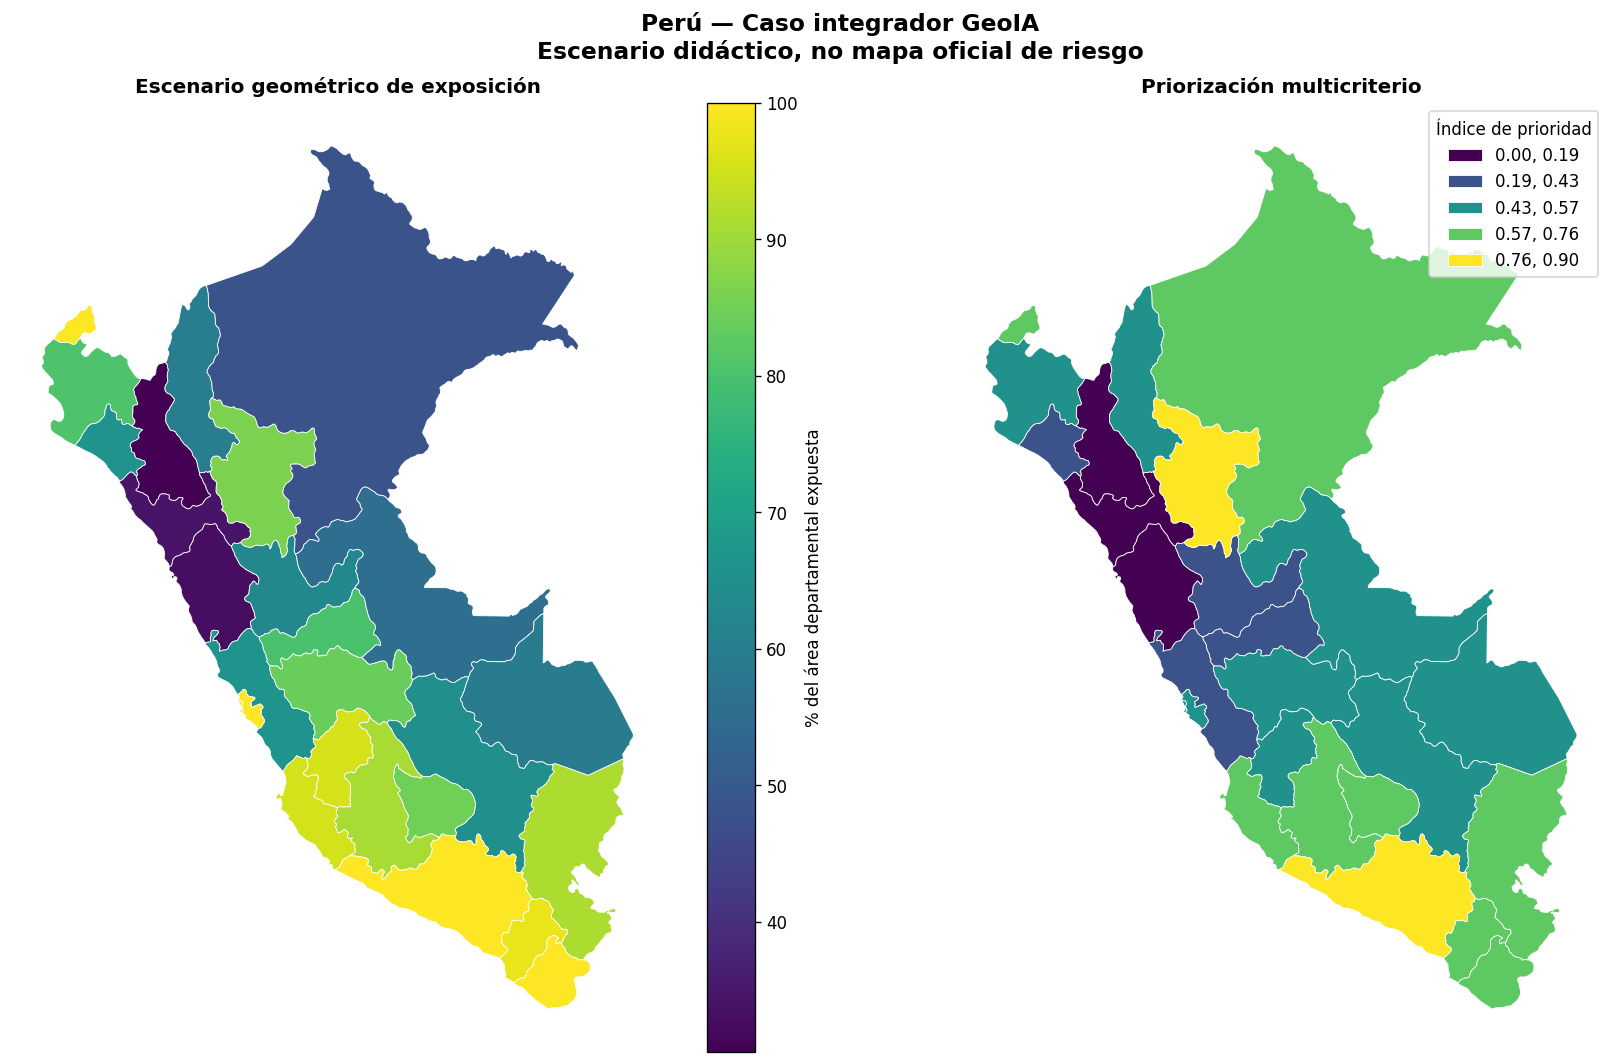

In [28]:
# produce una comparación visual:

# Mapa 1 (izquierda): muestra el porcentaje de área expuesta por departamento, es decir, cuánto territorio se encuentra dentro de la zona de influencia sísmica.

# Mapa 2 (derecha): muestra el índice multicriterio de prioridad, que integra exposición, magnitud máxima, energía sísmica y número de eventos influyentes.
fig, axes = plt.subplots(1, 2, figsize=(15, 9))

# 1. Primer mapa: exposición geométrica
# - Se colorea cada departamento según el porcentaje de área expuesta (%)
# - Se añade leyenda con etiqueta descriptiva
result.plot(
    ax=axes[0],
    column="pct_exposed",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "% del área departamental expuesta"}
)
axes[0].set_title("Escenario geométrico de exposición", fontweight="bold")
axes[0].set_axis_off()

# 2. Segundo mapa: índice multicriterio
# - Se colorea cada departamento según el índice de prioridad calculado
# - Se usa clasificación Fisher–Jenks para agrupar en clases naturales
result.plot(
    ax=axes[1],
    column="indice_prioridad",
    scheme="FisherJenks",
    k=k_final,
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"title": "Índice de prioridad"}
)
axes[1].set_title("Priorización multicriterio", fontweight="bold")
axes[1].set_axis_off()

# 3. Título general de la figura
plt.suptitle(
    "Perú — Caso integrador GeoIA\nEscenario didáctico, no mapa oficial de riesgo",
    fontsize=14,
    fontweight="bold"
)

# 4. Ajustar diseño y mostrar
plt.tight_layout()
plt.show()


## 5.9 Mapa interactivo final

El mapa final incluye:

- Departamentos coloreados por índice.
- Tooltip con métricas.
- Epicentros escalados por magnitud.
- Zona unionada de influencia.
- Selector de capas.

Antes de pasarlo a `folium`, todo vuelve a **EPSG:4326**.


**Este mapa interactivo combina tres capas principales:**

* Zona unionada de influencia sísmica → polígonos que representan la extensión espacial de los buffers de todos los sismos.

* Prioridad departamental → departamentos coloreados según el índice multicriterio de prioridad, con tooltip informativo.

* Eventos sísmicos M≥4.5 → círculos proporcionales a la magnitud, con popup detallado.

In [29]:
import folium
import branca
from folium.plugins import MarkerCluster

# 1. Reproyectar a WGS84 (EPSG:4326)
# Folium trabaja en coordenadas geográficas, por eso se transforman los datos.
peru_web = result.to_crs(4326).copy()
buffers_web = influence_union.to_crs(4326).copy()
quakes_web = quakes.to_crs(4326).copy()

# 2. Simplificar geometrías para mejorar rendimiento en el navegador
peru_web["geometry"] = peru_web.geometry.simplify(0.01, preserve_topology=True)
buffers_web["geometry"] = buffers_web.geometry.simplify(0.02, preserve_topology=True)

# 3. Definir escala de colores para el índice de prioridad
pmin = float(peru_web["indice_prioridad"].min())
pmax = float(peru_web["indice_prioridad"].max())
cmap_peru = branca.colormap.linear.YlOrRd_09.scale(pmin, pmax)
cmap_peru.caption = "Índice didáctico de prioridad"

# 4. Crear mapa base con fondo satelital de Esri
m_peru = folium.Map(
    location=[-9.19, -75.015],
    zoom_start=5,
    tiles="Esri WorldImagery",   # fondo satelital
    control_scale=True
)

# 5. Añadir capa de zona unionada de influencia sísmica
folium.GeoJson(
    buffers_web.to_json(),
    name="Zona unionada de influencia",
    style_function=lambda f: {
        "fillColor": "#6a51a3",
        "color": "#6a51a3",
        "weight": 1,
        "fillOpacity": 0.10
    }
).add_to(m_peru)

# 6. Añadir capa de prioridad departamental
# - Se colorea cada departamento según el índice de prioridad
# - Tooltip muestra atributos clave: clase, índice, % expuesto, eventos, magnitud máxima
folium.GeoJson(
    peru_web[[
        "departamento", "indice_prioridad", "prioridad",
        "pct_exposed", "eventos_influentes", "mag_max", "geometry"
    ]].to_json(),
    name="Prioridad departamental",
    style_function=lambda f: {
        "fillColor": cmap_peru(f["properties"]["indice_prioridad"]),
        "color": "#333333",
        "weight": 0.8,
        "fillOpacity": 0.72,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "departamento", "prioridad", "indice_prioridad",
            "pct_exposed", "eventos_influentes", "mag_max"
        ],
        aliases=[
            "Departamento", "Clase", "Índice",
            "% área expuesta", "Eventos influyentes", "Magnitud máxima"
        ],
        localize=True,
        sticky=False
    )
).add_to(m_peru)

# 7. Añadir capa de sismos como círculos
# - Cada círculo representa un evento M≥4.5
# - El tamaño depende de la magnitud
# - Popup muestra lugar, magnitud, profundidad y fecha
quake_group = folium.FeatureGroup(name="Sismos M≥4.5", show=False).add_to(m_peru)

for _, r in quakes_web.iterrows():
    folium.CircleMarker(
        location=[r.geometry.y, r.geometry.x],
        radius=max(2.5, 1.3 * float(r["mag"])),
        popup=(
            f"<b>{r['place']}</b><br>"
            f"M={r['mag']}<br>"
            f"Profundidad={r['depth_km']:.1f} km<br>"
            f"{r['time']}"
        ),
        weight=0.6,
        fill=True,
        fill_opacity=0.55
    ).add_to(quake_group)

# 8. Añadir colormap y control de capas
cmap_peru.add_to(m_peru)
folium.LayerControl(collapsed=False).add_to(m_peru)

# 9. Mostrar mapa interactivo
m_peru



In [30]:

# Guardar producto interactivo
out_html = Path("/content/caso_peru_prioridad_sismica.html") if Path("/content").exists() else Path("caso_peru_prioridad_sismica.html")
m_peru.save(out_html)
print("Mapa guardado en:", out_html)


Mapa guardado en: /content/caso_peru_prioridad_sismica.html



# 6. Qué debe saber defender el estudiante

Al terminar la clase debería poder explicar, sin ejecutar código:

1. **Por qué no se calculan buffers en EPSG:4326.**
2. Diferencia conceptual entre `overlay()` y `sjoin()`.
3. Para qué sirve `dissolve()` y por qué evita doble conteo espacial.
4. Por qué dos clasificadores pueden producir mapas visualmente distintos con la misma variable.
5. Por qué `contextily` y `folium` usan flujos de CRS diferentes.
6. Qué significa construir un índice multicriterio y por qué debe analizarse sensibilidad.
7. Por qué el caso Perú es una **priorización didáctica** y no un mapa oficial de riesgo.

---

## Ejercicio de extensión

Modifica una sola decisión metodológica y evalúa su impacto:

- cambiar los radios de influencia;
- usar solo sismos M≥5.0;
- reducir el período a 2021–2026;
- cambiar los pesos del índice;
- usar Quantiles en lugar de Fisher–Jenks.

**Entrega:** compara el ranking departamental y explica qué parte del resultado es estable y cuál depende de la especificación.


**Contexto**

Los radios didácticos (25/50/100/160 km) provienen de reglas empíricas de atenuación, pero no son curvas oficiales de intensidad. En el Perú, un M7.0 a 100 km en Ica produce sacudidas muy distintas a un M7.0 a 160 km en Puno (por efectos de sitio y amplificación de suelos blandos). Si el ranking cambia al mover los radios, la priorización depende más del supuesto pedagógico que de la realidad física.

**Pregunta**
¿Los departamentos identificados como prioritarios en la Parte 1 mantienen su puesto si cambiamos los radios de influencia en ±40%?

In [37]:
# Función: mismo flujo de las celdas 46, 48, 50 y 52, devolviendo resultado completo y zona de influencia
def correr_escenario_completo(factor):
    qb = quakes_m.copy()
    qb["radius_km"] = qb["mag"].apply(analysis_radius_km) * factor   # único cambio
    qb["energy_j"] = 10 ** (1.5 * qb["mag"] + 4.8)
    qb["geometry"] = [g.buffer(r * 1000) for g, r in zip(qb.geometry, qb["radius_km"])]
    infl = gpd.GeoDataFrame({"zona": ["unión de buffers"]},
                            geometry=[qb.geometry.union_all()], crs=PERU_LAEA)

    exp = gpd.overlay(peru_m[["departamento", "area_km2", "geometry"]],
                      infl[["geometry"]], how="intersection", keep_geom_type=True)
    exp["area_exposed_km2"] = exp.geometry.area / 1e6
    exp_dep = exp.groupby("departamento", as_index=False)["area_exposed_km2"].sum()
    res = peru_m.merge(exp_dep, on="departamento", how="left")
    res["area_exposed_km2"] = res["area_exposed_km2"].fillna(0)
    res["pct_exposed"] = 100 * res["area_exposed_km2"] / res["area_km2"]

    ij = gpd.sjoin(qb[["event_id", "mag", "depth_km", "energy_j", "geometry"]],
                   peru_m[["departamento", "geometry"]], how="inner", predicate="intersects")
    agg_ = ij.groupby("departamento").agg(
        eventos_influentes=("event_id", "nunique"),
        mag_max=("mag", "max"),
        energy_total=("energy_j", "sum")).reset_index()
    res = res.merge(agg_, on="departamento", how="left")
    res["eventos_influentes"] = res["eventos_influentes"].fillna(0).astype(int)
    res["mag_max"] = res["mag_max"].fillna(0)
    res["energy_total"] = res["energy_total"].fillna(0)
    res["log_energy"] = np.where(res["energy_total"] > 0, np.log10(res["energy_total"]), 0)

    for col in ["pct_exposed", "mag_max", "log_energy", "eventos_influentes"]:
        res[f"z_{col}"] = minmax(res[col])
    res["indice_prioridad"] = sum(w * res[c] for c, w in weights_A.items())
    res["rank"] = res["indice_prioridad"].rank(ascending=False, method="min")

    # Clases Fisher–Jenks (igual que la celda 52)
    k_ = min(5, max(2, res["indice_prioridad"].nunique()))
    fj_ = mapclassify.FisherJenks(res["indice_prioridad"].to_numpy(), k=k_)
    res["prioridad"] = [["Muy baja", "Baja", "Media", "Alta", "Muy alta"][:k_][i] for i in fj_.yb]
    return res, infl

# Correr los tres escenarios
escenarios = {"Original (×1.0)": 1.0, "Radios −40% (×0.6)": 0.6, "Radios +40% (×1.4)": 1.4}
resultados = {nombre: correr_escenario_completo(f) for nombre, f in escenarios.items()}

# Tabla de radios
tabla_radios = pd.DataFrame({
    "Magnitud": ["4.5–4.9", "5.0–5.9", "6.0–6.9", "≥ 7.0"],
    "Original (km)": [25, 50, 100, 160],
})
tabla_radios["−40% (km)"] = tabla_radios["Original (km)"] * 0.6
tabla_radios["+40% (km)"] = tabla_radios["Original (km)"] * 1.4
display(tabla_radios)

,Magnitud,Original (km),−40% (km),+40% (km)
0,4.5–4.9,25,15.0,35.0
1,5.0–5.9,50,30.0,70.0
2,6.0–6.9,100,60.0,140.0
3,≥ 7.0,160,96.0,224.0


In [38]:
print("Índice de prioridad (igual en los 3 escenarios):")
print("I = 0.40·E + 0.25·M + 0.20·log(Energía) + 0.15·N\n")
display(pd.DataFrame({
    "Variable": ["% área expuesta (E)", "Magnitud máxima (M)", "Energía acumulada, log10 (log E)", "N° eventos influyentes (N)"],
    "Peso": [weights_A["z_pct_exposed"], weights_A["z_mag_max"],
             weights_A["z_log_energy"], weights_A["z_eventos_influentes"]],
}))

Índice de prioridad (igual en los 3 escenarios):
I = 0.40·E + 0.25·M + 0.20·log(Energía) + 0.15·N



,Variable,Peso
0,% área expuesta (E),0.40
1,Magnitud máxima (M),0.25
2,"Energía acumulada, log10 (log E)",0.20
3,N° eventos influyentes (N),0.15


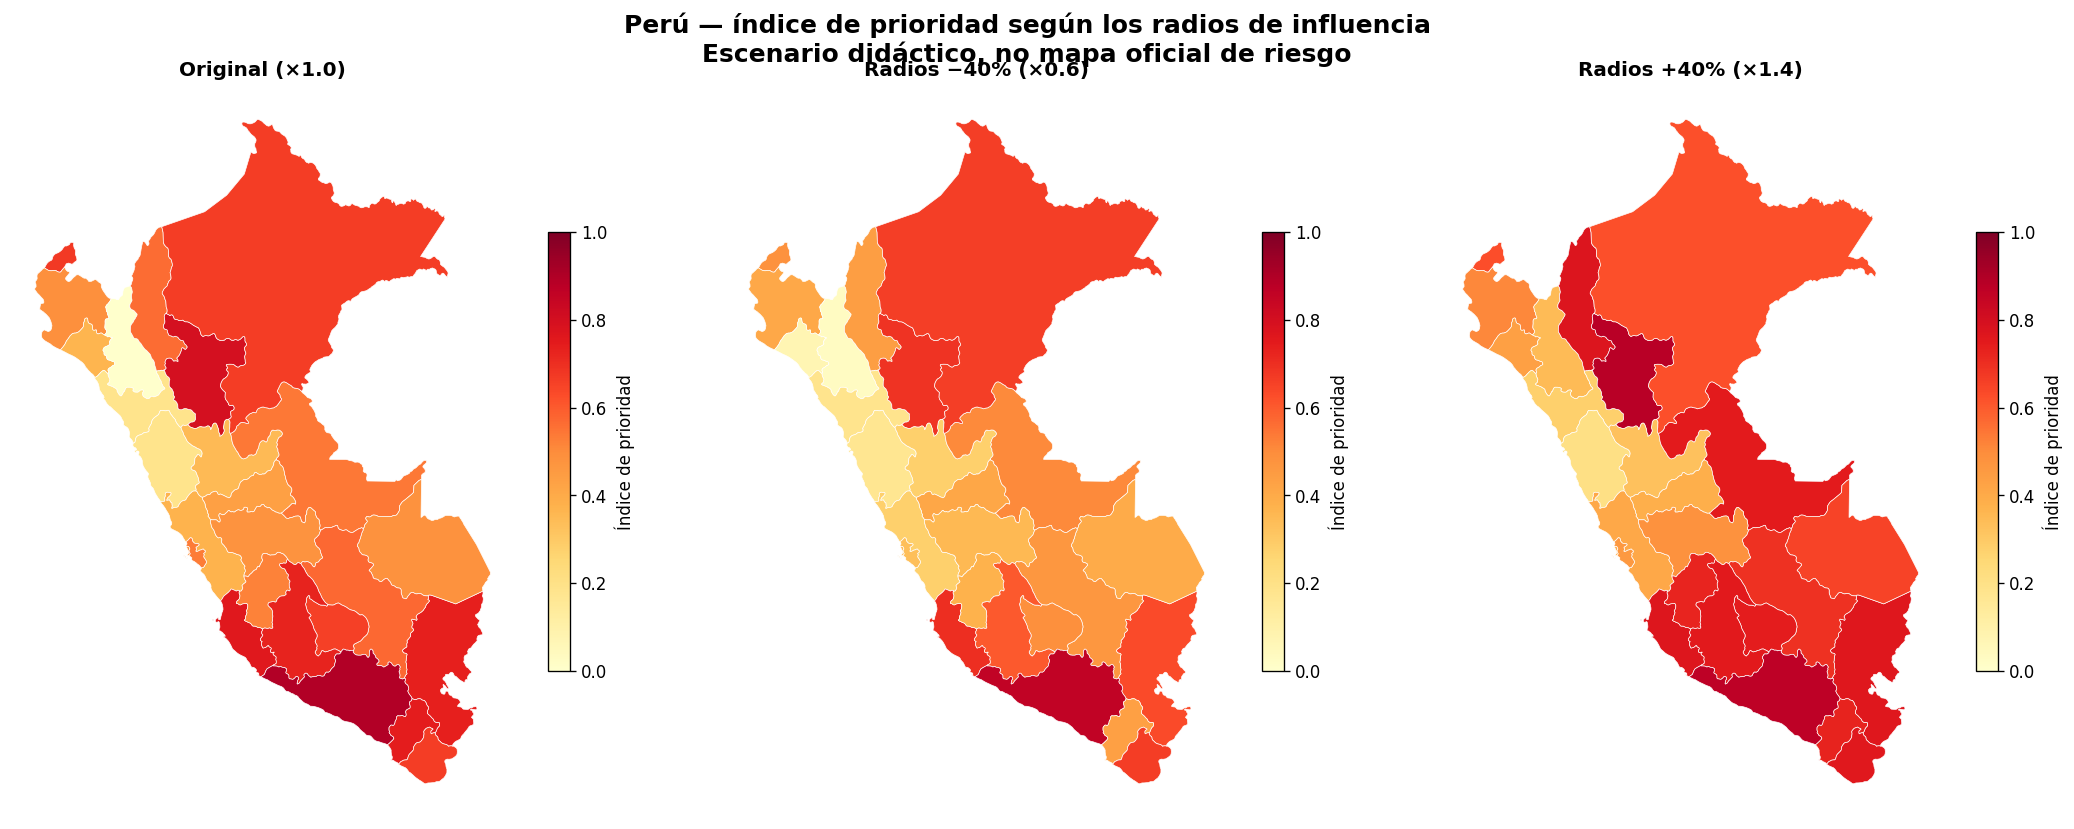

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (nombre, (res_, infl_)) in zip(axes, resultados.items()):
    res_.plot(ax=ax, column="indice_prioridad", cmap="YlOrRd", vmin=0, vmax=1,
              legend=True, edgecolor="white", linewidth=0.4,
              legend_kwds={"label": "Índice de prioridad", "shrink": 0.6})
    ax.set_title(nombre, fontweight="bold")
    ax.set_axis_off()

plt.suptitle("Perú — índice de prioridad según los radios de influencia\nEscenario didáctico, no mapa oficial de riesgo",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [43]:
import folium, branca

cmap_cmp = branca.colormap.linear.YlOrRd_09.scale(0, 1)
cmap_cmp.caption = "Índice didáctico de prioridad (escala común 0–1)"

# Mapa sin fondo por defecto: el satélite se agrega aparte y queda siempre visible
m_cmp = folium.Map(location=[-9.19, -75.015], zoom_start=5, tiles=None, control_scale=True)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satélite",
    overlay=True,
    control=False      # no aparece en el selector, siempre activo
).add_to(m_cmp)

for i, (nombre, (res_, infl_)) in enumerate(resultados.items()):
    r_web = res_.to_crs(4326).copy()
    z_web = infl_.to_crs(4326).copy()
    r_web["geometry"] = r_web.geometry.simplify(0.01, preserve_topology=True)
    z_web["geometry"] = z_web.geometry.simplify(0.02, preserve_topology=True)

    # Una sola capa por escenario (prioridad + zona de influencia), excluyentes entre sí
    grupo = folium.FeatureGroup(name=nombre, overlay=False, show=(i == 0))

    folium.GeoJson(
        r_web[["departamento", "rank", "indice_prioridad", "prioridad",
               "pct_exposed", "eventos_influentes", "mag_max", "geometry"]].to_json(),
        style_function=lambda f: {"fillColor": cmap_cmp(f["properties"]["indice_prioridad"]),
                                  "color": "#333333", "weight": 0.8, "fillOpacity": 0.72},
        tooltip=folium.GeoJsonTooltip(
            fields=["departamento", "rank", "prioridad", "indice_prioridad",
                    "pct_exposed", "eventos_influentes", "mag_max"],
            aliases=["Departamento", "Ranking", "Clase", "Índice",
                     "% área expuesta", "Eventos influyentes", "Magnitud máxima"],
            localize=True, sticky=False)
    ).add_to(grupo)

    # Contorno de la zona de influencia, encima y sin relleno para no tapar el tooltip
    folium.GeoJson(
        z_web.to_json(),
        style_function=lambda f: {"color": "#6a51a3", "weight": 2, "fill": False, "dashArray": "6 4"}
    ).add_to(grupo)

    grupo.add_to(m_cmp)

cmap_cmp.add_to(m_cmp)
folium.LayerControl(collapsed=False).add_to(m_cmp)
m_cmp

In [47]:
# ---------- 1. Tabla comparativa de rankings ----------
r_orig, r_menos, r_mas = [res_[["departamento", "rank"]] for res_, _ in resultados.values()]

comp = (r_orig.rename(columns={"rank": "Rank_Original"})
        .merge(r_menos.rename(columns={"rank": "Rank_-40%"}), on="departamento")
        .merge(r_mas.rename(columns={"rank": "Rank_+40%"}), on="departamento"))

comp["Cambio_-40%"] = comp["Rank_Original"] - comp["Rank_-40%"]   # positivo = sube, negativo = baja
comp["Cambio_+40%"] = comp["Rank_Original"] - comp["Rank_+40%"]

cols_rank = ["Rank_Original", "Rank_-40%", "Rank_+40%"]
comp = comp.sort_values("Rank_Original").reset_index(drop=True)

# Solo los 10 prioritarios del ranking original
display(comp.head(10))

# ---------- 2. Métricas de estabilidad ----------
print("Spearman original vs -40%:", round(comp["Rank_Original"].corr(comp["Rank_-40%"]), 3))
print("Spearman original vs +40%:", round(comp["Rank_Original"].corr(comp["Rank_+40%"]), 3))

for k in (3, 5, 10):
    top0 = set(comp.nsmallest(k, "Rank_Original")["departamento"])
    for etiqueta in ["-40%", "+40%"]:
        topx = set(comp.nsmallest(k, f"Rank_{etiqueta}")["departamento"])
        print(f"Top-{k} con {etiqueta}: {len(top0 & topx)} de {k} se mantienen")

,departamento,Rank_Original,Rank_-40%,Rank_+40%,Cambio_-40%,Cambio_+40%
0,Arequipa,1.0,1.0,2.0,0.0,-1.0
1,San Martín,2.0,3.0,1.0,-1.0,1.0
2,Ica,3.0,2.0,4.0,1.0,-1.0
3,Moquegua,4.0,13.0,10.0,-9.0,-6.0
4,Puno,5.0,6.0,5.0,-1.0,0.0
5,Ayacucho,6.0,7.0,7.0,-1.0,-1.0
6,Tumbes,7.0,10.0,14.0,-3.0,-7.0
7,Tacna,8.0,4.0,6.0,4.0,2.0
8,Loreto,9.0,5.0,15.0,4.0,-6.0
9,Apurímac,10.0,9.0,9.0,1.0,1.0


Spearman original vs -40%: 0.916
Spearman original vs +40%: 0.892
Top-3 con -40%: 3 de 3 se mantienen
Top-3 con +40%: 2 de 3 se mantienen
Top-5 con -40%: 3 de 5 se mantienen
Top-5 con +40%: 4 de 5 se mantienen
Top-10 con -40%: 9 de 10 se mantienen
Top-10 con +40%: 8 de 10 se mantienen


**Contexto**

La subducción peruana genera sismos superficiales en la costa (profundidad 10–40 km, muy destructivos — caso Pisco 2007 M8.0) y sismos profundos bajo la selva (500–650 km, como el M8.0 de Loreto en 2019, sentido en todo el continente pero con daño limitado). El índice actual de la Parte 1 trata igual un M7.0 a 10 km que uno a 600 km, lo cual sobreestima la prioridad de Loreto y San Martín si se interpreta como amenaza de daño.

**Pregunta**
¿Qué departamentos suben o bajan en prioridad cuando ponderamos la energía por profundidad (factor de atenuación)?

In [56]:
# ---------- Tabla de factores de atenuación (supuesto didáctico) ----------
tabla_factores = pd.DataFrame({
    "Categoría": ["Superficial", "Intermedio", "Profundo"],
    "Profundidad (km)": ["< 70", "70 – 300", "> 300"],
    "Factor de energía": [1.0, 0.5, 0.1],
})

# ---------- Aplicar la tabla al sjoin que ya tienes ----------
ij = influence_join.copy()
ij["depth_km"] = ij["depth_km"].fillna(ij["depth_km"].median())

ij["Categoría"] = pd.cut(
    ij["depth_km"],
    bins=[-np.inf, 70, 300, np.inf],
    labels=tabla_factores["Categoría"],
    right=False
)
ij = ij.merge(tabla_factores[["Categoría", "Factor de energía"]], on="Categoría", how="left")
ij["energy_prof"] = ij["energy_j"] * ij["Factor de energía"]

# ---------- Tabla de factores con número de sismos por categoría ----------
n_por_cat = (ij.drop_duplicates("event_id")
             .groupby("Categoría", observed=False)
             .size()
             .rename("n_sismos")
             .reset_index())

tabla_factores = tabla_factores.merge(n_por_cat, on="Categoría")
display(tabla_factores)

# ---------- Nuevo índice: igual al de la celda 52, cambiando solo la energía (peso 0.20) ----------
energia_prof = ij.groupby("departamento", as_index=False)["energy_prof"].sum()

res_p = result.merge(energia_prof, on="departamento", how="left")
res_p["energy_prof"] = res_p["energy_prof"].fillna(0)
res_p["log_energy_prof"] = np.where(res_p["energy_prof"] > 0, np.log10(res_p["energy_prof"]), 0)
res_p["z_log_energy_prof"] = minmax(res_p["log_energy_prof"])

res_p["indice_prof"] = (
    weights_A["z_pct_exposed"] * res_p["z_pct_exposed"]
    + weights_A["z_mag_max"] * res_p["z_mag_max"]
    + weights_A["z_log_energy"] * res_p["z_log_energy_prof"]       # <- única variable que cambia
    + weights_A["z_eventos_influentes"] * res_p["z_eventos_influentes"]
)

# ---------- Ranking y cambio de puesto ----------
res_p["rank_prof"] = res_p["indice_prof"].rank(ascending=False, method="min")
res_p["cambio"] = res_p["rank_A"] - res_p["rank_prof"]   # positivo = sube, negativo = baja

cols = ["departamento", "depth_med_km", "rank_A", "rank_prof", "cambio"]
tabla_prof = res_p[cols].sort_values("cambio", ascending=False)

print("\nSUBEN en prioridad:")
display(tabla_prof[tabla_prof["cambio"] > 0].round(1))

print("BAJAN en prioridad:")
display(tabla_prof[tabla_prof["cambio"] < 0].sort_values("cambio").round(1))

print("\nSpearman original vs con profundidad:",
      round(res_p["rank_A"].corr(res_p["rank_prof"]), 3))

,Categoría,Profundidad (km),Factor de energía,n_sismos
0,Superficial,< 70,1.0,530
1,Intermedio,70 – 300,0.5,501
2,Profundo,> 300,0.1,6



SUBEN en prioridad:


,departamento,depth_med_km,rank_A,rank_prof,cambio
21,Ayacucho,76.0,6.0,4.0,2.0
12,El Callao,65.6,19.0,17.0,2.0
13,Municipalidad Metropolitana de Lima,61.6,14.0,13.0,1.0
17,Huancavelica,79.8,15.0,14.0,1.0
25,Loreto,104.4,9.0,8.0,1.0
20,Apurímac,78.8,10.0,9.0,1.0


BAJAN en prioridad:


,departamento,depth_med_km,rank_A,rank_prof,cambio
18,Madre de Dios,27.6,17.0,19.0,-2.0
14,Ucayali,131.8,13.0,15.0,-2.0
24,Tacna,114.5,8.0,10.0,-2.0
23,Moquegua,94.6,4.0,5.0,-1.0
0,Puno,180.5,5.0,6.0,-1.0



Spearman original vs con profundidad: 0.991


In [58]:
# ---------- Mapa interactivo: una capa por versión del índice ----------
m_prof = folium.Map(location=[-9.19, -75.015], zoom_start=5, tiles=None, control_scale=True)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satélite", overlay=True, control=False
).add_to(m_prof)

versiones = {"Índice original": "indice_prioridad",
             "Con profundidad (energía ponderada)": "indice_prof"}

for i, (nombre, col) in enumerate(versiones.items()):
    g = res_p.to_crs(4326)[["departamento", "rank_A", "rank_prof", "cambio", col, "geometry"]].copy()
    g = g.rename(columns={col: "indice_mostrado"})
    g["geometry"] = g.geometry.simplify(0.01, preserve_topology=True)

    grupo = folium.FeatureGroup(name=nombre, overlay=False, show=(i == 0))
    folium.GeoJson(
        g.to_json(),
        style_function=lambda f: {"fillColor": cmap_cmp(f["properties"]["indice_mostrado"]),
                                  "color": "#333333", "weight": 0.8, "fillOpacity": 0.72},
        tooltip=folium.GeoJsonTooltip(
            fields=["departamento", "indice_mostrado", "rank_A", "rank_prof", "cambio"],
            aliases=["Departamento", "Índice", "Ranking original", "Ranking con profundidad",
                     "Cambio de puesto (+ sube, − baja)"],
            localize=True, sticky=False)
    ).add_to(grupo)
    grupo.add_to(m_prof)

cmap_cmp.add_to(m_prof)
folium.LayerControl(collapsed=False).add_to(m_prof)
m_prof